# Proyecto RaSa: Entregable 3 · Conclusión del entendimiento de datos

Presentado por:

* DIANA CAROLINA LEAL MARTINEZ
* DIEGO ALEJANDRO FIGUEREDO SALAMANCA
* MARIA CAMILA REYES GIL
* SILVIA CARDENAS SANTOS

Curso: Modelado de Datos y ETL · Universidad de los Andes · 2026

**Objetivo:** validar y documentar si es posible realizar los análisis de la matriz de temas analíticos de RaSA, qué ajustes requiere su planteamiento y qué información adicional hace falta, además se identifican explícitamente las columnas que permiten integrar las fuentes F1 a F4, se listan los supuestos y dudas para que la empresa los resuelva.

**Enfoque del notebook:**

1. Se parte de los hallazgos del Entregable 1 (perfilamiento) y del Entregable 2 (calidad).
2. Se aplica una **preparación mínima en memoria** (Spark) para medir qué errores son recuperables.
3. Se validan las llaves de integración y su cardinalidad.
4. Se ejecuta un **prototipo de cada análisis** (1.a a 4.b) para respaldar cada conclusión con evidencia.

El documento `analisis_entregable_3.md` consolida la matriz de viabilidad, las columnas de integración, los supuestos y las dudas.

## 1. Configuración del entorno y conexión

In [1]:
import os
import sys
import json

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

IN_CODESPACES = os.environ.get("CODESPACES") == "true"

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark

if IN_COLAB:
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"

ENVIRONMENT = (
    "colab" if IN_COLAB
    else "codespaces" if IN_CODESPACES
    else "local"
)

print(f"Entorno detectado: {ENVIRONMENT}")

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as sf
from pyspark.sql.functions import col, when, trim, lit

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

Entorno detectado: local


### Configuración del controlador e inicio de sesión Spark

Se reutiliza la configuración del Entregable 2: el conector JDBC de MySQL (Connector/J 9.7.0) se descarga la primera vez en `~/.miid4103/jars`.

In [2]:
from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR.name}')

Conector JDBC: mysql-connector-j-9.7.0.jar


In [3]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.x en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

spark = (SparkSession.builder
         .master('local[*]')
         .appName('Proyecto-RaSa-Entregable-3')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    # comportamiento de Spark 3.5
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print(f'Spark {spark.version}')

Spark 4.3.0


### Credenciales y conexión de solo lectura

Las credenciales se pueden escribir en `db_user` y `db_psswd` o guardar en un archivo local `~/.miid4103/credenciales.json` con la forma `{"user": "...", "password": "..."}`, que queda fuera del repositorio. 
El parámetro `sessionVariables=transaction_read_only=ON` hace que el servidor **rechace cualquier escritura** durante la sesión.

In [4]:
db_host = '157.253.236.120'
db_port = 8080
db_database = 'RaSaTransaccional'
db_user = ''
db_psswd = ''

ruta_credenciales = Path.home() / '.miid4103' / 'credenciales.json'
if (not db_user or not db_psswd) and ruta_credenciales.exists():
    credenciales = json.loads(ruta_credenciales.read_text(encoding='utf-8'))
    db_user, db_psswd = credenciales['user'], credenciales['password']

if not db_user or not db_psswd:
    raise ValueError('Complete db_user y db_psswd antes de continuar')
jdbc_opciones = ('useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'
                 '&sessionVariables=transaction_read_only=ON')
db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/{db_database}?{jdbc_opciones}'

# En Colab, suba Diccionario.xlsx a /content/
PATH = '/content/' if ENVIRONMENT == 'colab' else './'

In [5]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

# Verificación: base actual y modo de solo lectura de la sesión
obtener_dataframe_de_bd(db_connection_string,
    '(SELECT DATABASE() AS base_actual, @@session.transaction_read_only AS solo_lectura) AS v',
    db_user, db_psswd).show()

+-----------------+------------+
|      base_actual|solo_lectura|
+-----------------+------------+
|RaSaTransaccional|           1|
+-----------------+------------+



> La sesión apunta a `RaSaTransaccional` con `solo_lectura = 1`: el notebook no puede insertar, actualizar ni borrar datos en la base. Toda la preparación posterior ocurre sobre DataFrames de Spark en memoria.

## 2. Carga de las fuentes F1 a F4

In [6]:
sql_fuente_areas_servicio = '(SELECT * FROM RaSaTransaccional.FuenteAreasDeServicio_Copia_E) AS t'
sql_fuente_tipos_beneficio = '(SELECT * FROM RaSaTransaccional.FuenteTiposBeneficio_Copia_E) AS b'
sql_fuente_planes_beneficio = '(SELECT * FROM RaSaTransaccional.FuentePlanesBeneficio_Copia_E) AS p'
sql_condiciones_pago = '(SELECT * FROM RaSaTransaccional.FuenteCondicionesDePago_Copia_E) AS c'

fuente_areas_servicio = obtener_dataframe_de_bd(db_connection_string, sql_fuente_areas_servicio, db_user, db_psswd)
fuente_tipos_beneficio = obtener_dataframe_de_bd(db_connection_string, sql_fuente_tipos_beneficio, db_user, db_psswd)
fuente_planes_beneficio = obtener_dataframe_de_bd(db_connection_string, sql_fuente_planes_beneficio, db_user, db_psswd)
condiciones_pago = obtener_dataframe_de_bd(db_connection_string, sql_condiciones_pago, db_user, db_psswd)

FUENTES = {
    'F1 FuenteAreasDeServicio_Copia_E': fuente_areas_servicio,
    'F2 FuenteTiposBeneficio_Copia_E': fuente_tipos_beneficio,
    'F3 FuentePlanesBeneficio_Copia_E': fuente_planes_beneficio,
    'F4 FuenteCondicionesDePago_Copia_E': condiciones_pago,
}
display(pd.DataFrame([{'fuente': nombre, 'filas': df.count(), 'columnas': len(df.columns),
                       'filas_distintas': df.dropDuplicates().count()}
                      for nombre, df in FUENTES.items()]))

,fuente,filas,columnas,filas_distintas
0,F1 FuenteAreasDeServicio_Copia_E,188815,9,145242
1,F2 FuenteTiposBeneficio_Copia_E,849,9,578
2,F3 FuentePlanesBeneficio_Copia_E,36036,11,27543
3,F4 FuenteCondicionesDePago_Copia_E,31,3,24


> Los volúmenes coinciden con los entregables anteriores: 188.815, 849, 36.036 y 31 filas, que se reducen a 145.242, 578, 27.543 y 24 filas distintas al quitar duplicados exactos.

## 3. Diccionario de datos frente a la estructura real

Se compara cada campo del diccionario (`Diccionario.xlsx`) con las columnas reales de las tablas. La comparación ignora mayúsculas y tildes para separar diferencias de forma de las diferencias de nombre.

In [7]:
import unicodedata
from difflib import get_close_matches

def normalizar(texto):
    texto = unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode()
    return texto.strip().lower()

ruta_diccionario = Path(PATH) / 'Diccionario.xlsx'
if ruta_diccionario.exists():
    hoja = pd.read_excel(ruta_diccionario, header=None).dropna(axis=1, how='all')
    fila_encabezado = hoja.index[hoja.iloc[:, 0].astype(str).str.strip() == 'Tabla'][0]   # el encabezado no está en la primera fila
    diccionario = hoja.iloc[fila_encabezado + 1:].set_axis(hoja.iloc[fila_encabezado].str.strip(), axis=1)
    diccionario['Tabla'] = diccionario['Tabla'].ffill()
    diccionario = diccionario.dropna(subset=['Campo'])
    columnas_reales = {nombre.split(' ')[1]: df.columns for nombre, df in FUENTES.items()}

    comparacion = []
    for _, fila in diccionario.iterrows():
        tabla = fila['Tabla'].strip()
        tabla_real = get_close_matches(tabla, columnas_reales, n=1, cutoff=0.8)
        tabla_real = tabla_real[0] if tabla_real else None
        reales = columnas_reales.get(tabla_real, [])
        campo = fila['Campo'].strip()
        normalizadas = {normalizar(c): c for c in reales}
        if campo in reales:
            campo_real, estado = campo, 'Coincide'
        elif normalizar(campo) in normalizadas:
            campo_real, estado = normalizadas[normalizar(campo)], 'Solo cambian mayúsculas o tildes'
        else:
            parecido = get_close_matches(normalizar(campo), normalizadas, n=1, cutoff=0.8)
            campo_real = normalizadas[parecido[0]] if parecido else None
            estado = 'Nombre distinto' if parecido else 'No existe en la tabla'
        comparacion.append({'tabla_diccionario': tabla, 'tabla_real': tabla_real, 'campo_diccionario': campo,
                            'campo_real': campo_real, 'estado': estado,
                            'descripcion': fila['Descripcion']})
    comparacion = pd.DataFrame(comparacion)
    print('Resumen de la comparación:')
    display(comparacion['estado'].value_counts().to_frame('campos'))
    print('Tablas del diccionario cuyo nombre no coincide exactamente:')
    display(comparacion.loc[comparacion.tabla_diccionario != comparacion.tabla_real,
                            ['tabla_diccionario', 'tabla_real']].drop_duplicates())
    print('Campos con diferencias de nombre:')
    display(comparacion[comparacion.estado == 'Nombre distinto'][['tabla_real', 'campo_diccionario', 'campo_real']])
    sin_documentar = [(t, c) for t, cs in columnas_reales.items() for c in cs
                      if c not in set(comparacion.loc[comparacion.tabla_real == t, 'campo_real'])]
    print('Columnas reales que no aparecen en el diccionario:', sin_documentar)
else:
    print('No se encontró Diccionario.xlsx; se omite la comparación.')

Resumen de la comparación:


,campos
estado,
Coincide,20
Solo cambian mayúsculas o tildes,8
Nombre distinto,4


Tablas del diccionario cuyo nombre no coincide exactamente:


,tabla_diccionario,tabla_real
12,FuentesPlanesBeneficio_Copia_E,FuentePlanesBeneficio_Copia_E


Campos con diferencias de nombre:


,tabla_real,campo_diccionario,campo_real
0,FuenteAreasDeServicio_Copia_E,idAreaServicio_T,IdAreaDeServicio_T
15,FuentePlanesBeneficio_Copia_E,idCondicionesDePagoCopago_T,IdCondicionDePagoCopago_T
16,FuentePlanesBeneficio_Copia_E,idCondicionesDePagoCoseguro_T,IdCondicionDePagoCoseguro_T
27,FuenteTiposBeneficio_Copia_E,EstaCubiertoPorSeguro,EstaCubiertaPorSeguro


Columnas reales que no aparecen en el diccionario: []


> **Lectura del resultado.** Todos los campos del diccionario existen en las tablas, pero la documentación no está alineada con la base:
>
> * La tabla `FuentesPlanesBeneficio_Copia_E` del diccionario se llama `FuentePlanesBeneficio_Copia_E` en la base.
> * De los 32 campos documentados, 20 coinciden exactamente y 8 difieren solo en mayúsculas o tildes.
> * Cuatro campos tienen un nombre distinto: `idAreaServicio_T` (real `IdAreaDeServicio_T`), `idCondicionesDePagoCopago_T` y `idCondicionesDePagoCoseguro_T` (reales `IdCondicionDePagoCopago_T` e `IdCondicionDePagoCoseguro_T`) y `EstaCubiertoPorSeguro` (real `EstaCubiertaPorSeguro`).
> * No hay columnas reales sin documentar.
>
> **Lo que aporta el diccionario al entendimiento:**
>
> * `Area` está en **millas cuadradas** y `Densidad` en **habitantes por milla cuadrada**.
> * `Fecha` significa algo distinto en cada fuente: creación del área (F1), definición del tipo de beneficio (F2) y **oferta del beneficio en el plan** (F3), donde los análisis por rango de fechas deben usar la fecha de F3.
> * `Tipo` admite `Copago`, `Coseguro` y `Anticipado`, aunque `Anticipado` no aparece en los datos (Entregable 2).
>
> **Lo que el diccionario no resuelve:** no existe catálogo para `IdNivelServicio_T` ni tabla de proveedores (solo el código `IdProveedor_T`). Tampoco hay una tabla de grupos de áreas de servicio, aunque la matriz de RaSA la menciona en F1.

## 4. Hallazgo estructural: cada área de servicio pertenece a un solo plan

En el Entregable 1 se observó que `NombreAreaDeServicio` contiene textos como `BEST Life Georgia83502GA0020003-0120171107`. Aquí se valida que ese nombre incrusta el **código del plan** (`83502GA0020003-01`) y el **año** (`2017`). Esto define el significado real de un área de servicio.

In [ ]:
# Código de plan: 5 dígitos de proveedor + 2 letras de estado + 7 dígitos + guion + variante de 2 dígitos
PATRON_PLAN = r'(\d{5}[A-Z]{2}\d{7}-\d{2})'

f1_estructura = (fuente_areas_servicio.dropDuplicates()
    .withColumn('PlanEnNombre', sf.regexp_extract('NombreAreaDeServicio', PATRON_PLAN, 1))
    .withColumn('AnioEnNombre', sf.regexp_extract('NombreAreaDeServicio', PATRON_PLAN + r'(\d{4})', 2))
    .withColumn('SufijoId', sf.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)))

print('Ejemplos de descomposición del nombre del área:')
display(f1_estructura.filter(col('IdAreaDeServicio_T').isNotNull())
        .select('IdAreaDeServicio_T', 'NombreAreaDeServicio', 'PlanEnNombre', 'AnioEnNombre', 'SufijoId')
        .dropDuplicates(['IdAreaDeServicio_T']).orderBy('IdAreaDeServicio_T').limit(5).toPandas())

print('Filas de F1 cuyo nombre contiene un código de plan:',
      f1_estructura.filter(col('PlanEnNombre') != '').count(), 'de', f1_estructura.count())
con_id = f1_estructura.filter(col('IdAreaDeServicio_T').isNotNull())
print('Filas con ID donde el año del nombre coincide con el sufijo del ID:',
      con_id.filter(col('AnioEnNombre') == col('SufijoId')).count(), 'de', con_id.count())

print('Atributos por área de servicio:')
display(con_id.groupBy('IdAreaDeServicio_T')
        .agg(sf.countDistinct('NombreAreaDeServicio').alias('nombres'),
             sf.countDistinct('PlanEnNombre').alias('planes'),
             sf.countDistinct('Estado').alias('estados'),
             sf.countDistinct('Condado').alias('condados'))
        .agg(sf.count('*').alias('areas'),
             sf.max('nombres').alias('max_nombres_por_area'),
             sf.max('planes').alias('max_planes_por_area'),
             sf.max('estados').alias('max_estados_por_area'),
             sf.round(sf.avg('condados'), 1).alias('condados_promedio_por_area'),
             sf.max('condados').alias('max_condados_por_area')).toPandas())

# Validar que el plan de F3 es el mismo plan que aparece en el nombre de su área en F1
area_nombre = con_id.select('IdAreaDeServicio_T', 'PlanEnNombre').distinct()
f3_con_area = (fuente_planes_beneficio.dropDuplicates()
               .filter(trim(col('IdPlan_T')) != '')
               .join(area_nombre, 'IdAreaDeServicio_T'))
print('Filas de F3 con plan y área presentes en F1:', f3_con_area.count(),
      '| el plan de F3 es el del nombre del área:', f3_con_area.filter(col('PlanEnNombre') == trim(col('IdPlan_T'))).count())

Ejemplos de descomposición del nombre del área:


,IdAreaDeServicio_T,NombreAreaDeServicio,PlanEnNombre,AnioEnNombre,SufijoId
0,12018,NoVa10207VA0380001-0620189007,10207VA0380001-06,2018,2018
1,42018,NoVa10207VA0380001-0620189496,10207VA0380001-06,2018,2018
2,52018,NoVa10207VA0380001-0620189211,10207VA0380001-06,2018,2018
3,62018,NoVa10207VA0380001-0620188948,10207VA0380001-06,2018,2018
4,82018,NoVa10207VA0430006-0120188948,10207VA0430006-01,2018,2018


Filas de F1 cuyo nombre contiene un código de plan: 145242 de 145242


Filas con ID donde el año del nombre coincide con el sufijo del ID: 140401 de 140401
Atributos por área de servicio:


,areas,max_nombres_por_area,max_planes_por_area,max_estados_por_area,condados_promedio_por_area,max_condados_por_area
0,5409,1,1,1,21.7,154


Filas de F3 con plan y área presentes en F1: 20766 | el plan de F3 es el del nombre del área: 20766


> **Conclusión del hallazgo:**
>
> * El 100 % de los nombres de área contiene un código de plan y el año del nombre coincide con los 4 últimos dígitos de `IdAreaDeServicio_T`.
> * Cada una de las 5.409 áreas tiene **un solo nombre, un solo plan y un solo estado**, donde agrupa en promedio cerca de 22 condados (máximo 154).
> * En F3, el plan de cada fila es **siempre** el mismo plan que figura en el nombre de su área en F1.
>
> **Significado de una fila de F1:** un condado (`IdGeografia_T`) incluido en el área de servicio de **un plan específico** en un año, esta área de servicio no es una zona geográfica compartida por varios planes o proveedores, sino la huella geográfica de un plan.
>
> **Implicación para los análisis 2 y 3:** preguntas como "¿cuántos planes hay por área?" o "¿qué áreas cubren menos de dos proveedores?" tienen respuesta trivial (siempre 1), puesto que La unidad geográfica comparable es el **condado** (`IdGeografia_T`) y por agregación el **estado**.

## 5. Preparación mínima en memoria

El objetivo **no es construir el ETL definitivo**, sino medir qué errores del Entregable 2 son recuperables y con qué regla, para decidir la viabilidad de los análisis, cada regla se aplica solo después de mostrar la evidencia que la justifica puesto que las constantes se derivan de los propios datos y no se modifica ninguna tabla de la base.

In [9]:
resumen_preparacion = []

def registrar_regla(fuente, problema, regla, filas_afectadas, filas_recuperadas):
    resumen_preparacion.append({'fuente': fuente, 'problema': problema, 'regla': regla,
                                'filas_afectadas': filas_afectadas, 'filas_recuperadas': filas_recuperadas})

### 5.1 F1 · Áreas de servicio

In [10]:
# Regla 1: duplicados exactos
f1 = fuente_areas_servicio.dropDuplicates()
registrar_regla('F1', 'Filas duplicadas exactas', 'dropDuplicates()',
                fuente_areas_servicio.count() - f1.count(), fuente_areas_servicio.count() - f1.count())

# Regla 2: IdAreaDeServicio_T nulo -> se recupera por nombre (cada nombre corresponde a un único ID)
nombre_a_id = (f1.filter(col('IdAreaDeServicio_T').isNotNull())
               .groupBy('NombreAreaDeServicio')
               .agg(sf.countDistinct('IdAreaDeServicio_T').alias('ids_por_nombre'),
                    sf.min('IdAreaDeServicio_T').alias('IdAreaPorNombre')))
print('Nombres de área asociados a más de un ID:', nombre_a_id.filter(col('ids_por_nombre') > 1).count())

f1 = (f1.join(nombre_a_id.select('NombreAreaDeServicio', 'IdAreaPorNombre'), 'NombreAreaDeServicio', 'left')
        .withColumn('IdAreaDeServicio', sf.coalesce('IdAreaDeServicio_T', 'IdAreaPorNombre'))
        .withColumn('IdPlan', sf.regexp_extract('NombreAreaDeServicio', PATRON_PLAN, 1))
        .withColumn('Anio', sf.regexp_extract('NombreAreaDeServicio', PATRON_PLAN + r'(\d{4})', 2).cast('int')))
nulos_antes = f1.filter(col('IdAreaDeServicio_T').isNull()).count()
nulos_despues = f1.filter(col('IdAreaDeServicio').isNull()).count()
print(f'Filas con IdAreaDeServicio nulo: antes {nulos_antes:,} | después {nulos_despues:,}')
registrar_regla('F1', 'IdAreaDeServicio_T nulo', 'Recuperar por NombreAreaDeServicio', nulos_antes, nulos_antes - nulos_despues)

# Regla 3: año 1800 -> el año real está en el nombre del área (y en el sufijo del ID)
print('Año registrado en Fecha frente al año contenido en el nombre:')
f1.groupBy('Fecha', 'Anio').count().orderBy('Fecha', 'Anio').show()
anio_1800 = f1.filter(col('Fecha') == 1800).count()
registrar_regla('F1', 'Fecha = 1800', 'Año desde el nombre del área / sufijo del ID', anio_1800,
                f1.filter((col('Fecha') == 1800) & col('Anio').isin(2017, 2018)).count())

Nombres de área asociados a más de un ID: 0


Filas con IdAreaDeServicio nulo: antes 4,841 | después 3
Año registrado en Fecha frente al año contenido en el nombre:


+-----+----+-----+
|Fecha|Anio|count|
+-----+----+-----+
| 1800|2017| 2666|
| 1800|2018| 2175|
| 2017|2017|76318|
| 2018|2018|64083|
+-----+----+-----+



> Cada nombre de área corresponde a un único ID, por lo que los IDs nulos se recuperan casi en su totalidad, solo quedan 3 filas cuyo nombre no aparece con ID en ninguna otra fila. Las filas con `Fecha = 1800` se reparten entre 2017 y 2018 según el año incrustado en el nombre, lo que confirma la conclusión del Entregable 2.

In [ ]:
# Regla 4: IdGeografia_T. Un mismo (Estado, Condado) aparece con dos códigos, se verifica si uno es el triple del otro
geo_por_condado = (f1.filter(col('IdGeografia_T').isNotNull())
                   .groupBy('Estado', 'Condado')
                   .agg(sf.min('IdGeografia_T').alias('geo_min'),
                        sf.max('IdGeografia_T').alias('geo_max'),
                        sf.countDistinct('IdGeografia_T').alias('ids')))
display(geo_por_condado.agg(
    sf.count('*').alias('condados'),
    sf.sum(when(col('ids') == 2, 1).otherwise(0)).alias('condados_con_2_codigos'),
    sf.sum(when((col('ids') == 2) & (col('geo_max') == 3 * col('geo_min')), 1).otherwise(0)).alias('segundo_codigo_es_el_triple'),
    sf.max('ids').alias('max_codigos_por_condado')).toPandas())

FIPS_MAXIMO = 56045  # mayor código FIPS de condado en EE. UU. (Weston County, Wyoming)
print('Condados cuyo código mínimo sigue fuera del rango FIPS (solo aparecen con el código triplicado):')
display(geo_por_condado.filter(col('geo_min') > FIPS_MAXIMO).toPandas())
geo_por_condado = geo_por_condado.withColumn(
    'IdGeografia', when(col('geo_min') > FIPS_MAXIMO, (col('geo_min') / 3).cast('int')).otherwise(col('geo_min')))

nulas_geo = f1.filter(col('IdGeografia_T').isNull()).count()
f1 = f1.join(geo_por_condado.select('Estado', 'Condado', 'IdGeografia'), ['Estado', 'Condado'], 'left')
triplicadas = f1.filter(col('IdGeografia_T') == 3 * col('IdGeografia')).count()
print(f'Filas con código triplicado: {triplicadas:,} | filas con IdGeografia_T nulo: {nulas_geo:,}')
print('Filas con IdGeografia nulo después:', f1.filter(col('IdGeografia').isNull()).count())
print('Códigos fuera del rango FIPS después:', f1.filter(col('IdGeografia') > FIPS_MAXIMO).select('IdGeografia').distinct().count())
print('Condados (Estado, Condado):', f1.select('Estado', 'Condado').distinct().count(),
      '| códigos IdGeografia distintos:', f1.select('IdGeografia').distinct().count())
# Los 2 primeros dígitos del FIPS identifican el estado: todos los condados de un estado deben compartirlos
print('Estados con más de un prefijo FIPS de estado:',
      f1.groupBy('Estado').agg(sf.countDistinct((col('IdGeografia') / 1000).cast('int')).alias('prefijos'))
        .filter(col('prefijos') > 1).count())
registrar_regla('F1', 'IdGeografia_T triplicado', 'Código mínimo por (Estado, Condado); ÷3 si queda fuera de rango',
                triplicadas, triplicadas)
registrar_regla('F1', 'IdGeografia_T nulo', 'Código por (Estado, Condado)', nulas_geo,
                nulas_geo - f1.filter(col('IdGeografia').isNull()).count())

,condados,condados_con_2_codigos,segundo_codigo_es_el_triple,max_codigos_por_condado
0,2282,2053,2053,2


Condados cuyo código mínimo sigue fuera del rango FIPS (solo aparecen con el código triplicado):


,Estado,Condado,geo_min,geo_max,ids
0,Maine,Aroostook County,69009,69009,1


Filas con código triplicado: 24,207 | filas con IdGeografia_T nulo: 4,841


Filas con IdGeografia nulo después: 0


Códigos fuera del rango FIPS después: 0


Condados (Estado, Condado): 2282 | códigos IdGeografia distintos: 2282


Estados con más de un prefijo FIPS de estado: 0


> En **todos** los condados con dos códigos (2.053), el segundo es exactamente el triple del primero (por ejemplo, Autauga County: 1001 y 3003), por eso aparecían 4.251 códigos para 2.282 condados y 1.521 códigos fuera del rango FIPS. 

Al tomar el código mínimo por (Estado y Condado) queda un código por condado y se recuperan también los códigos nulos, un condado (Aroostook County, Maine) solo aparece con su código triplicado (69009 = 3 × 23003) y se corrige dividiendo entre 3, tras la corrección no quedan códigos fuera de rango y todos los condados de cada estado comparten el prefijo FIPS del estado, lo que valida la regla.

In [12]:
# Regla 5: PoblacionAct y Area por condado
medidas_condado = (f1.groupBy('IdGeografia')
                   .agg(sf.min('PoblacionAct').alias('pob_min'), sf.max('PoblacionAct').alias('pob_max'),
                        sf.min('Area').alias('area_min'), sf.max('Area').alias('area_max')))
display(medidas_condado.agg(
    sf.count('*').alias('condados'),
    sf.sum(when(col('pob_max') > col('pob_min'), 1).otherwise(0)).alias('con_2_poblaciones'),
    sf.sum(when((col('pob_max') > col('pob_min')) & (sf.abs(col('pob_max') / col('pob_min') - 10000) < 1), 1)
           .otherwise(0)).alias('la_mayor_es_x10000'),
    sf.sum(when(col('area_min') < 0, 1).otherwise(0)).alias('con_area_negativa'),
    sf.sum(when((col('area_min') < 0) & (col('area_min') == -col('area_max')), 1).otherwise(0)).alias('negativa_es_la_opuesta'),
    sf.sum(when(col('area_max').isNull(), 1).otherwise(0)).alias('sin_area')).toPandas())

pob_inflada = f1.join(medidas_condado, 'IdGeografia').filter(col('PoblacionAct') > col('pob_min')).count()
area_negativa = f1.filter(col('Area') < 0).count()
f1 = (f1.join(medidas_condado.select('IdGeografia', col('pob_min').alias('Poblacion')), 'IdGeografia', 'left')
        .withColumn('AreaMillas2', sf.abs('Area'))
        .withColumn('DensidadCalculada', sf.round(col('Poblacion') / col('AreaMillas2'))))
print('Filas donde Densidad difiere de Poblacion / Area (más de 5 hab/mi²) tras corregir:',
      f1.filter(sf.abs(col('Densidad') - col('DensidadCalculada')) > 5).count())
registrar_regla('F1', 'PoblacionAct multiplicada por 10.000', 'Población mínima por condado', pob_inflada, pob_inflada)
registrar_regla('F1', 'Area negativa', 'Valor absoluto', area_negativa, area_negativa)

,condados,con_2_poblaciones,la_mayor_es_x10000,con_area_negativa,negativa_es_la_opuesta,sin_area
0,2282,1485,1485,1474,1474,31


Filas donde Densidad difiere de Poblacion / Area (más de 5 hab/mi²) tras corregir: 0


> Las poblaciones atípicas del Entregable 2 son la población real **multiplicada por 10.000** y las áreas negativas son el **opuesto** del área real. Con ambas correcciones la densidad reportada coincide en el 100 % de las filas con `Poblacion / Area`, lo que valida las dos reglas, eso sí las ciudades independientes de Virginia siguen sin área (dato faltante en origen), aunque el análisis de concentración usa población, por lo que sí está completa.

In [13]:
areas_condados = (f1.filter(col('IdAreaDeServicio').isNotNull())
                  .select('IdAreaDeServicio', 'IdPlan', sf.substring('IdPlan', 1, 5).cast('int').alias('IdProveedor'),
                          'Anio', 'IdGeografia', 'Estado', 'Condado')
                  .dropDuplicates().cache())
condados = (f1.groupBy('IdGeografia')
            .agg(sf.first('Estado').alias('Estado'), sf.first('Condado').alias('Condado'),
                 sf.min('Poblacion').alias('Poblacion'), sf.max('AreaMillas2').alias('AreaMillas2'))
            .cache())

filas = areas_condados.count()
llaves = areas_condados.select('IdAreaDeServicio', 'IdGeografia').distinct().count()
print(f'areas_condados: {filas:,} filas | combinaciones únicas (área, condado): {llaves:,}')
display(areas_condados.groupBy('Anio').agg(
    sf.countDistinct('IdAreaDeServicio').alias('areas'), sf.countDistinct('IdPlan').alias('planes'),
    sf.countDistinct('IdProveedor').alias('proveedores'), sf.countDistinct('IdGeografia').alias('condados'),
    sf.countDistinct('Estado').alias('estados')).orderBy('Anio').toPandas())
print(f'condados: {condados.count():,} condados de {condados.select("Estado").distinct().count()} estados')

areas_condados: 121,032 filas | combinaciones únicas (área, condado): 121,032


,Anio,areas,planes,proveedores,condados,estados
0,2017,2783,189,72,1553,27
1,2018,2626,272,86,1875,33


condados: 2,282 condados de 35 estados


> Tras la preparación F1 queda con una fila por (área y condado) sin colisiones, afirmando que contiene las 5.409 áreas declaradas por RaSA, que cubren 2.282 condados de 35 estados.

### 5.2 F3 · Beneficios de los planes

In [14]:
OFFSET_AREA = fuente_areas_servicio.agg(sf.max('IdAreaDeServicio_T')).first()[0]
OFFSET_BENEFICIO = fuente_tipos_beneficio.agg(sf.max('IdTipoBeneficio_T')).first()[0]
print('Mayor IdAreaDeServicio_T en F1:', OFFSET_AREA, '| Mayor IdTipoBeneficio_T en F2:', OFFSET_BENEFICIO)

f3 = (fuente_planes_beneficio.dropDuplicates()
      .withColumn('SufijoArea', sf.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4))
      .withColumn('AnioTexto', sf.regexp_extract('Fecha', r'(\d{4})', 1)))
registrar_regla('F3', 'Filas duplicadas exactas', 'dropDuplicates()',
                fuente_planes_beneficio.count() - f3.count(), fuente_planes_beneficio.count() - f3.count())

print('Año de Fecha (filas) frente a los 4 últimos dígitos de IdAreaDeServicio_T (columnas):')
f3.groupBy('AnioTexto').pivot('SufijoArea').count().orderBy('AnioTexto').show()

Mayor IdAreaDeServicio_T en F1: 117872018 | Mayor IdTipoBeneficio_T en F2: 1055


Año de Fecha (filas) frente a los 4 últimos dígitos de IdAreaDeServicio_T (columnas):


+---------+----+-----+-----+----+----+
|AnioTexto|null| 2017| 2018|4035|4036|
+---------+----+-----+-----+----+----+
|     1920|NULL|  759|  825|NULL|NULL|
|     2017| 825|11468| NULL| 805|NULL|
|     2018| 754| NULL|11328|NULL| 779|
+---------+----+-----+-----+----+----+



> Dos patrones saltan a la vista:
>
> * Las filas con año **1920** traen un área cuyo sufijo es 2017 o 2018, así que el año real es recuperable.
> * Hay IDs de área que terminan en **4035 y 4036**, esos sufijos no son años, sino 2017 + 2018 y 2018 + 2018, por lo que se deduce que al ID le sumaron un valor de más.

Se verifica la hipótesis de que el valor sumado es el mayor ID de F1 (117.872.018) y la equivalente para los beneficios huérfanos con el mayor ID de F2 (1.055).

In [15]:
area_plan = areas_condados.select('IdAreaDeServicio', col('IdPlan').alias('PlanDelArea')).distinct()

sospechosas = (f3.filter(col('SufijoArea').isin('4035', '4036'))
               .withColumn('AreaCorregida', col('IdAreaDeServicio_T') - OFFSET_AREA))
verificacion_area = sospechosas.join(area_plan, sospechosas.AreaCorregida == area_plan.IdAreaDeServicio, 'left')
display(verificacion_area.agg(
    sf.count('*').alias('filas_sufijo_4035_4036'),
    sf.count('PlanDelArea').alias('area_corregida_existe_en_F1'),
    sf.sum(when(col('PlanDelArea') == trim(col('IdPlan_T')), 1).otherwise(0)).alias('y_es_del_mismo_plan')).toPandas())

ids_f2 = fuente_tipos_beneficio.select(col('IdTipoBeneficio_T').alias('IdF2')).distinct()
fuera_de_rango = (f3.filter(col('IdTipoBeneficio_T') > OFFSET_BENEFICIO)
                  .withColumn('BeneficioCorregido', col('IdTipoBeneficio_T') - OFFSET_BENEFICIO))
display(fuera_de_rango.join(ids_f2, fuera_de_rango.BeneficioCorregido == ids_f2.IdF2, 'left').agg(
    sf.count('*').alias('filas_beneficio_mayor_a_maximo_F2'),
    sf.count('IdF2').alias('beneficio_corregido_existe_en_F2')).toPandas())

,filas_sufijo_4035_4036,area_corregida_existe_en_F1,y_es_del_mismo_plan
0,1584,1433,1433


,filas_beneficio_mayor_a_maximo_F2,beneficio_corregido_existe_en_F2
0,1584,1584


> Ambas hipótesis se confirman:
>
> * **Áreas:** al restar 117.872.018, el 90,5 % de los IDs corruptos (1.433 de 1.584 filas) apunta a un área de F1 **del mismo plan** que indica F3, mientras que el resto apunta a áreas que tampoco existen en F1.
> * **Beneficios:** al restar 1.055, el 100 % de los IDs huérfanos existe en F2, dado que los 107 "beneficios inexistentes" del Entregable 2 son beneficios válidos con el ID desplazado.

In [16]:
f3 = (f3
      .withColumn('IdAreaDeServicio', when(col('SufijoArea').isin('4035', '4036'), col('IdAreaDeServicio_T') - OFFSET_AREA)
                  .otherwise(col('IdAreaDeServicio_T')))
      .withColumn('IdTipoBeneficio', when(col('IdTipoBeneficio_T') > OFFSET_BENEFICIO, col('IdTipoBeneficio_T') - OFFSET_BENEFICIO)
                  .otherwise(col('IdTipoBeneficio_T')))
      .withColumn('Anio', when(col('AnioTexto') == '1920', sf.substring(col('IdAreaDeServicio').cast('string'), -4, 4))
                  .otherwise(col('AnioTexto')).cast('int'))
      .join(area_plan, 'IdAreaDeServicio', 'left')
      .withColumn('IdPlan', when(trim(col('IdPlan_T')) == '', col('PlanDelArea')).otherwise(trim(col('IdPlan_T'))))
      .withColumnRenamed('IdProveedor_T', 'IdProveedor'))

registrar_regla('F3', 'IdAreaDeServicio_T con sufijo 4035/4036', f'Restar {OFFSET_AREA}', sospechosas.count(),
                verificacion_area.filter(col('PlanDelArea') == trim(col('IdPlan_T'))).count())
registrar_regla('F3', f'IdTipoBeneficio_T mayor a {OFFSET_BENEFICIO}', f'Restar {OFFSET_BENEFICIO}', fuera_de_rango.count(),
                fuera_de_rango.join(ids_f2, fuera_de_rango.BeneficioCorregido == ids_f2.IdF2).count())
registrar_regla('F3', 'Fecha 1920-12-31', 'Año desde el sufijo de IdAreaDeServicio', f3.filter(col('AnioTexto') == '1920').count(),
                f3.filter((col('AnioTexto') == '1920') & col('Anio').isin(2017, 2018)).count())
registrar_regla('F3', 'Fecha con formato "Dec 31,YYYY"', 'Extraer el año de 4 dígitos', f3.filter(col('Fecha').startswith('Dec')).count(),
                f3.filter(col('Fecha').startswith('Dec') & col('Anio').isNotNull()).count())
plan_vacio = f3.filter(trim(col('IdPlan_T')) == '').count()
registrar_regla('F3', 'IdPlan_T vacío', 'Plan del área de servicio en F1', plan_vacio,
                f3.filter((trim(col('IdPlan_T')) == '') & col('IdPlan').isNotNull()).count())

print('Coherencia IdProveedor = 5 primeros dígitos de IdPlan:',
      f3.filter(col('IdPlan').isNotNull() & (sf.substring('IdPlan', 1, 5).cast('int') != col('IdProveedor'))).count(),
      'filas incoherentes')

Coherencia IdProveedor = 5 primeros dígitos de IdPlan: 0 filas incoherentes


In [17]:
planes_beneficio = (f3.select('IdPlan', 'IdProveedor', 'IdTipoBeneficio', 'IdAreaDeServicio', 'IdNivelServicio_T',
                              'IdCondicionDePagoCopago_T', 'IdCondicionDePagoCoseguro_T', 'Anio',
                              'valorCopago', 'valorCoseguro', 'cantidadLimite')
                    .dropDuplicates().cache())

areas_f1 = areas_condados.select('IdAreaDeServicio').distinct()
beneficios_f2 = fuente_tipos_beneficio.select(col('IdTipoBeneficio_T').alias('IdTipoBeneficio')).distinct()
display(planes_beneficio.groupBy('Anio').count().orderBy('Anio').toPandas().set_index('Anio').T)
display(pd.DataFrame([{
    'filas': planes_beneficio.count(),
    'IdPlan_nulo': planes_beneficio.filter(col('IdPlan').isNull()).count(),
    'IdAreaDeServicio_nulo': planes_beneficio.filter(col('IdAreaDeServicio').isNull()).count(),
    'area_sin_correspondencia_en_F1': planes_beneficio.filter(col('IdAreaDeServicio').isNotNull())
                                      .join(areas_f1, 'IdAreaDeServicio', 'left_anti').count(),
    'IdTipoBeneficio_nulo': planes_beneficio.filter(col('IdTipoBeneficio').isNull()).count(),
    'beneficio_sin_correspondencia_en_F2': planes_beneficio.filter(col('IdTipoBeneficio').isNotNull())
                                           .join(beneficios_f2, 'IdTipoBeneficio', 'left_anti').count(),
}]))
planes_sin_areas = (planes_beneficio.filter(col('IdPlan').isNotNull()).select('IdPlan').distinct()
                    .join(areas_condados.select('IdPlan').distinct(), 'IdPlan', 'left_anti'))
print('Planes de F3 sin ninguna área en F1:', planes_sin_areas.count())

Anio,2017,2018
count,13857,13686


,filas,IdPlan_nulo,IdAreaDeServicio_nulo,area_sin_correspondencia_en_F1,IdTipoBeneficio_nulo,beneficio_sin_correspondencia_en_F2
0,27543,136,1579,2317,1412,0


Planes de F3 sin ninguna área en F1: 18


> **Lo que queda sin recuperar en F3:**
>
> * 1.412 filas sin `IdTipoBeneficio` y 1.579 sin `IdAreaDeServicio`, dado que son nulos en origen sin patrón recuperable.
> * 136 filas sin plan: su área tampoco está en F1.
> * 2.317 filas cuya área no existe en F1, en su mayoría de **18 planes que no tienen ninguna área en F1**.
>
> Ya no quedan beneficios huérfanos y todas las filas tienen año 2017 o 2018, estas filas faltantes se excluyen solo de los análisis que necesitan la columna ausente.

### 5.3 F2 · Tipos de beneficio y F4 · Condiciones de pago

In [18]:
SI = ['Yes', 'Si', 'True']
NO = ['No', 'Nein', 'False']
BOOLEANOS = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
             'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']

tipos_beneficio = fuente_tipos_beneficio.dropDuplicates()
for c in BOOLEANOS:
    tipos_beneficio = tipos_beneficio.withColumn(
        c, when(col(c).isin(SI), 'Si').when(col(c).isin(NO), 'No').otherwise('Indeterminado'))

dim_beneficio = (tipos_beneficio.select(col('IdTipoBeneficio_T').alias('IdTipoBeneficio'),
                                        col('Nombre').alias('NombreBeneficio')).distinct().cache())
print(f"dim_beneficio: {dim_beneficio.count()} filas | {dim_beneficio.select('IdTipoBeneficio').distinct().count()} IDs | "
      f"{dim_beneficio.select('NombreBeneficio').distinct().count()} nombres")

print('Claves (IdTipoBeneficio_T, Fecha) con más de un valor por atributo, después de homologar:')
colisiones = (tipos_beneficio.groupBy('IdTipoBeneficio_T', 'Fecha')
              .agg(*[sf.countDistinct(c).alias(c) for c in BOOLEANOS + ['UnidadDelLimite']]))
display(colisiones.agg(sf.count('*').alias('claves'),
                       *[sf.sum(when(col(c) > 1, 1).otherwise(0)).alias(c) for c in BOOLEANOS + ['UnidadDelLimite']]).toPandas())

dim_beneficio: 178 filas | 178 IDs | 178 nombres
Claves (IdTipoBeneficio_T, Fecha) con más de un valor por atributo, después de homologar:


,claves,EsEHB,EstaCubiertaPorSeguro,TieneLimiteCuantitativo,ExcluidoDelDesembolsoMaximoDentroDeLaRed,ExcluidoDelDesembolsoMaximoFueraDeLaRed,UnidadDelLimite
0,218,43,45,54,18,100,64


> El nombre del beneficio es **1 a 1** con su ID (178 IDs y 178 nombres), así que la dimensión `(IdTipoBeneficio, NombreBeneficio)` se integra con F3 **sin multiplicar filas**. 

Las colisiones del Entregable 2 persisten en los atributos booleanos y en la unidad del límite incluso después de homologar idiomas, esos atributos no se pueden usar hasta que RaSA defina cuál es el valor vigente por beneficio y año, entonces los análisis 1 y 4 solo necesitan el nombre, por lo que no se ven afectados.

In [19]:
condiciones = condiciones_pago.dropDuplicates()
print('IDs de F4 con más de una descripción:')
condiciones.groupBy('IdCondicionesDePago_T').agg(sf.collect_set('Descripcion').alias('descripciones'))\
    .filter(sf.size('descripciones') > 1).show(truncate=False)

dim_condicion = (condiciones.groupBy('IdCondicionesDePago_T')
                 .agg(sf.countDistinct('Descripcion').alias('n'), sf.first('Descripcion').alias('d'))
                 .select(col('IdCondicionesDePago_T').alias('IdCondicion'),
                         when(col('n') > 1, sf.concat(lit('Ambigua (ID '), col('IdCondicionesDePago_T').cast('string'), lit(')')))
                         .otherwise(col('d')).alias('Condicion'))
                 .cache())

print('Descripciones registradas con más de un ID:')
condiciones.groupBy('Descripcion').agg(sf.sort_array(sf.collect_set('IdCondicionesDePago_T')).alias('ids'))\
    .filter(sf.size('ids') > 1).orderBy('Descripcion').show(truncate=False)

uso = (planes_beneficio.select(lit('Copago').alias('rol'), col('IdCondicionDePagoCopago_T').alias('IdCondicion'))
       .unionByName(planes_beneficio.select(lit('Coseguro').alias('rol'), col('IdCondicionDePagoCoseguro_T').alias('IdCondicion')))
       .groupBy('rol', 'IdCondicion').count()
       .join(dim_condicion, 'IdCondicion', 'left')
       .join(condiciones.groupBy(col('IdCondicionesDePago_T').alias('IdCondicion'))
             .agg(sf.concat_ws(' / ', sf.collect_set('Tipo')).alias('TipoEnF4')), 'IdCondicion', 'left')
       .orderBy('rol', 'IdCondicion'))
print('Condiciones usadas por F3 según la columna (rol) en que aparecen:')
display(uso.toPandas())
display(uso.groupBy('rol').agg(sf.countDistinct('IdCondicion').alias('ids_usados'),
                               sf.countDistinct('Condicion').alias('descripciones_usadas')).toPandas())

IDs de F4 con más de una descripción:
+---------------------+------------------------------------------------+
|IdCondicionesDePago_T|descripciones                                   |
+---------------------+------------------------------------------------+
|204                  |[Copay per Stay after deductible, Copay per Day]|
+---------------------+------------------------------------------------+

Descripciones registradas con más de un ID:


+-------------------------------+----------+
|Descripcion                    |ids       |
+-------------------------------+----------+
|Coinsurance                    |[45, 135] |
|Copay                          |[238, 714]|
|Copay per Stay                 |[221, 663]|
|Copay per Stay after deductible|[68, 204] |
|No Charge                      |[9, 51]   |
|No Charge after deductible     |[18, 207] |
|Not Applicable                 |[34, 36]  |
+-------------------------------+----------+

Condiciones usadas por F3 según la columna (rol) en que aparecen:


,IdCondicion,rol,count,Condicion,TipoEnF4
0,17,Copago,9,Copay per Day after deductible,Copago
1,34,Copago,12468,Not Applicable,Copagado
2,51,Copago,469,No Charge,Copago
3,68,Copago,22,Copay per Stay after deductible,SinTipoCopago
4,85,Copago,3,Copay per Day before deductible,Copago
5,102,Copago,42,Copay per Stay before deductible,Copago
6,136,Copago,19,Copay per Stay with deductible,Copago
7,153,Copago,223,Copay after deductible,Copago
8,170,Copago,99,Copay before deductible,Copago
9,187,Copago,39,Copay with deductible,Copago


,rol,ids_usados,descripciones_usadas
0,Copago,14,14
1,Coseguro,5,5


> **Condiciones de pago:**
>
> * El **rol** de cada condición (copago o coseguro) lo determina la columna de F3 en que se usa, no la columna `Tipo` de F4, por ejemplo, el ID 34 "Not Applicable" tiene `Tipo = Copagado` y el ID 9 "No Charge" tiene `Tipo = Coseguridad`, por eso las etiquetas erróneas de `Tipo` no impiden el análisis.
> * F3 usa **14 IDs de condición de copago y 5 de coseguro**, donde los de coseguro coinciden con los 5 declarados por RaSA y los de copago quedan uno por debajo de los 15 declarados. Además F4 tiene IDs que F3 nunca usa (119, 663 y 714) mientras que F3 usa los IDs 68 y 221 cuyo `Tipo` en F4 es erróneo (`SinTipoCopago` y `NaN`).
> * El ID 204 sigue siendo ambiguo ("Copay per Day" frente a "Copay per Stay after deductible"), así que se marca como `Ambigua (ID 204)` para no compararlo con ninguna de las dos.
> * Varias descripciones tienen dos IDs (por ejemplo "Copay": 238 y 714), entonces para comparar costos se agrupa por **descripción**, no por ID.

In [20]:
display(pd.DataFrame(resumen_preparacion))

,fuente,problema,regla,filas_afectadas,filas_recuperadas
0,F1,Filas duplicadas exactas,dropDuplicates(),43573,43573
1,F1,IdAreaDeServicio_T nulo,Recuperar por NombreAreaDeServicio,4841,4838
2,F1,Fecha = 1800,Año desde el nombre del área / sufijo del ID,4841,4841
3,F1,IdGeografia_T triplicado,"Código mínimo por (Estado, Condado); ÷3 si que...",24207,24207
4,F1,IdGeografia_T nulo,"Código por (Estado, Condado)",4841,4841
5,F1,PoblacionAct multiplicada por 10.000,Población mínima por condado,4841,4841
6,F1,Area negativa,Valor absoluto,4793,4793
7,F3,Filas duplicadas exactas,dropDuplicates(),8493,8493
8,F3,IdAreaDeServicio_T con sufijo 4035/4036,Restar 117872018,1584,1433
9,F3,IdTipoBeneficio_T mayor a 1055,Restar 1055,1584,1584


> **Resumen de la preparación.** Casi todos los errores del Entregable 2 siguen **patrones deterministas** y se recuperan con reglas simples y verificables como desplazamientos de ID, multiplicaciones, signos invertidos y años sustituidos. 

Lo que no se recupera son nulos sin patrón, las áreas de 17 planes ausentes en F1 y las colisiones de atributos de F2. Estas reglas son el insumo de la etapa de ETL, previos a confirmación de RaSA.

## 6. Significado de una fila tras la preparación

In [21]:
llave_f3 = ['IdPlan', 'IdTipoBeneficio', 'IdAreaDeServicio', 'IdNivelServicio_T', 'Anio']
completos = planes_beneficio.dropna(subset=llave_f3)
print(f'F3 con llave completa: {completos.count():,} filas | combinaciones únicas de {llave_f3}: '
      f'{completos.select(llave_f3).distinct().count():,}')

variacion = (planes_beneficio.dropna(subset=['IdPlan', 'IdTipoBeneficio'])
             .groupBy('IdPlan', 'IdTipoBeneficio', 'IdNivelServicio_T', 'Anio')
             .agg(sf.countDistinct('IdAreaDeServicio').alias('areas'),
                  sf.countDistinct('valorCopago').alias('copagos'),
                  sf.countDistinct('valorCoseguro').alias('coseguros'),
                  sf.countDistinct('cantidadLimite').alias('limites')))
display(variacion.agg(sf.count('*').alias('grupos_plan_beneficio_nivel_anio'),
                      sf.sum(when(col('areas') > 1, 1).otherwise(0)).alias('presentes_en_mas_de_un_area'),
                      sf.sum(when(col('copagos') > 1, 1).otherwise(0)).alias('copago_varia_entre_areas'),
                      sf.sum(when(col('coseguros') > 1, 1).otherwise(0)).alias('coseguro_varia_entre_areas'),
                      sf.sum(when(col('limites') > 1, 1).otherwise(0)).alias('limite_varia_entre_areas')).toPandas())

print('Niveles de servicio presentes por (plan, beneficio, área, año):')
completos.groupBy('IdPlan', 'IdTipoBeneficio', 'IdAreaDeServicio', 'Anio')\
    .agg(sf.countDistinct('IdNivelServicio_T').alias('niveles')).groupBy('niveles').count().orderBy('niveles').show()

beneficios_plan = (planes_beneficio.filter(col('IdPlan').isNotNull() & col('IdTipoBeneficio').isNotNull())
                   .drop('IdAreaDeServicio').dropDuplicates()
                   .join(dim_beneficio, 'IdTipoBeneficio', 'left')
                   .join(dim_condicion.select(col('IdCondicion').alias('IdCondicionDePagoCopago_T'),
                                              col('Condicion').alias('CondicionCopago')), 'IdCondicionDePagoCopago_T', 'left')
                   .join(dim_condicion.select(col('IdCondicion').alias('IdCondicionDePagoCoseguro_T'),
                                              col('Condicion').alias('CondicionCoseguro')), 'IdCondicionDePagoCoseguro_T', 'left')
                   .cache())
llave_bp = ['IdPlan', 'IdTipoBeneficio', 'IdNivelServicio_T', 'Anio']
print(f'beneficios_plan: {beneficios_plan.count():,} filas | combinaciones únicas de {llave_bp}: '
      f'{beneficios_plan.select(llave_bp).distinct().count():,}')

F3 con llave completa: 24,416 filas | combinaciones únicas de ['IdPlan', 'IdTipoBeneficio', 'IdAreaDeServicio', 'IdNivelServicio_T', 'Anio']: 24,416


,grupos_plan_beneficio_nivel_anio,presentes_en_mas_de_un_area,copago_varia_entre_areas,coseguro_varia_entre_areas,limite_varia_entre_areas
0,25198,206,0,0,0


Niveles de servicio presentes por (plan, beneficio, área, año):


+-------+-----+
|niveles|count|
+-------+-----+
|      1|  347|
|      2| 2529|
|      3| 6337|
+-------+-----+



beneficios_plan: 25,198 filas | combinaciones únicas de ['IdPlan', 'IdTipoBeneficio', 'IdNivelServicio_T', 'Anio']: 25,198


> **Significado de una fila de F3 (preparada):** las condiciones de costo (copago, coseguro, condición de pago y cantidad límite) de **un tipo de beneficio** en **un nivel de servicio** de **un plan** registradas para **una de las áreas de servicio** del plan en **un año**.
>
> * La combinación (plan, beneficio, área, nivel, año) es única.
> * Los costos **no cambian entre áreas** del mismo plan, dado que la mayoría de los registros aparece en una sola área, aunque el plan tenga muchas, de modo que F3 trae una muestra de áreas por plan y no el detalle completo.
> * Por eso para los análisis de costos se usa `beneficios_plan` con una fila por plan, beneficio, nivel y año con el nombre del beneficio y la descripción de las condiciones.
> * La mayoría de las combinaciones trae los 3 niveles de servicio, pero algunas traen solo 1 o 2.
>
> **Resumen del grano de cada conjunto preparado:**
>
> | Conjunto | Una fila representa |
> |---|---|
> | `areas_condados` (F1) | un condado incluido en el área de servicio de un plan en un año |
> | `condados` (F1) | un condado (código FIPS) con su población y su área en millas cuadradas |
> | `planes_beneficio` (F3) | un beneficio de un plan en un nivel de servicio, área y año |
> | `beneficios_plan` (F3) | un beneficio de un plan en un nivel de servicio y año (sin área) |
> | `dim_beneficio` (F2) | un tipo de beneficio |
> | `dim_condicion` (F4) | una condición de pago |

## 7. Columnas que permiten integrar las fuentes

Para cada relación se mide qué porcentaje de las filas hijas encuentra su llave en la tabla padre y **cuántas filas tiene la tabla padre por llave**, si este último valor es mayor que 1 un `JOIN` directo multiplica filas , por lo que ;a medición se hace con los datos crudos y con los datos preparados.

In [22]:
def validar_llave(relacion, etapa, hijo, col_hijo, padre, col_padre):
    llaves_padre = padre.select(col(col_padre).alias('_llave')).filter(col('_llave').isNotNull())
    por_llave = llaves_padre.groupBy('_llave').count()
    con_valor = hijo.select(col(col_hijo).alias('_hijo')).filter(col('_hijo').isNotNull())
    cruzan = con_valor.join(por_llave, col('_hijo') == col('_llave'), 'left_semi').count()
    filas_join = con_valor.join(llaves_padre, col('_hijo') == col('_llave')).count()
    n = con_valor.count()
    return {'relacion': relacion, 'etapa': etapa, 'filas_hijo': hijo.count(), 'con_llave': n,
            'cruzan': cruzan, 'pct_cruzan': round(100 * cruzan / n, 2) if n else None,
            'max_filas_padre_por_llave': por_llave.agg(sf.max('count')).first()[0],
            'filas_tras_inner_join': filas_join}

f1_planes = fuente_areas_servicio.withColumn('PlanEnNombre', sf.regexp_extract('NombreAreaDeServicio', PATRON_PLAN, 1))
validaciones = [
    validar_llave('F3.IdAreaDeServicio_T -> F1.IdAreaDeServicio_T', 'crudo',
                  fuente_planes_beneficio, 'IdAreaDeServicio_T', fuente_areas_servicio, 'IdAreaDeServicio_T'),
    validar_llave('F3.IdAreaDeServicio_T -> F1.IdAreaDeServicio_T', 'preparado',
                  planes_beneficio, 'IdAreaDeServicio', areas_condados, 'IdAreaDeServicio'),
    validar_llave('F3.IdPlan_T -> plan en F1.NombreAreaDeServicio', 'crudo',
                  fuente_planes_beneficio, 'IdPlan_T', f1_planes.select('PlanEnNombre').distinct(), 'PlanEnNombre'),
    validar_llave('F3.IdPlan_T -> plan en F1.NombreAreaDeServicio', 'preparado',
                  planes_beneficio, 'IdPlan', areas_condados.select('IdPlan').distinct(), 'IdPlan'),
    validar_llave('F3.IdTipoBeneficio_T -> F2.IdTipoBeneficio_T', 'crudo',
                  fuente_planes_beneficio, 'IdTipoBeneficio_T', fuente_tipos_beneficio, 'IdTipoBeneficio_T'),
    validar_llave('F3.IdTipoBeneficio_T -> F2.IdTipoBeneficio_T', 'preparado',
                  planes_beneficio, 'IdTipoBeneficio', dim_beneficio, 'IdTipoBeneficio'),
    validar_llave('F3.IdCondicionDePagoCopago_T -> F4.IdCondicionesDePago_T', 'crudo',
                  fuente_planes_beneficio, 'IdCondicionDePagoCopago_T', condiciones_pago, 'IdCondicionesDePago_T'),
    validar_llave('F3.IdCondicionDePagoCopago_T -> F4.IdCondicionesDePago_T', 'preparado',
                  planes_beneficio, 'IdCondicionDePagoCopago_T', dim_condicion, 'IdCondicion'),
    validar_llave('F3.IdCondicionDePagoCoseguro_T -> F4.IdCondicionesDePago_T', 'crudo',
                  fuente_planes_beneficio, 'IdCondicionDePagoCoseguro_T', condiciones_pago, 'IdCondicionesDePago_T'),
    validar_llave('F3.IdCondicionDePagoCoseguro_T -> F4.IdCondicionesDePago_T', 'preparado',
                  planes_beneficio, 'IdCondicionDePagoCoseguro_T', dim_condicion, 'IdCondicion'),
    validar_llave('F1.IdGeografia_T -> condado', 'preparado',
                  areas_condados, 'IdGeografia', condados, 'IdGeografia'),
]
display(pd.DataFrame(validaciones))

print('Reglas de coherencia entre llaves (datos preparados):')
display(pd.DataFrame([
    {'regla': 'IdProveedor = 5 primeros dígitos de IdPlan',
     'filas_evaluadas': planes_beneficio.filter(col('IdPlan').isNotNull()).count(),
     'filas_que_cumplen': planes_beneficio.filter(sf.substring('IdPlan', 1, 5).cast('int') == col('IdProveedor')).count()},
    {'regla': 'Anio (F3) = 4 últimos dígitos de IdAreaDeServicio',
     'filas_evaluadas': planes_beneficio.filter(col('IdAreaDeServicio').isNotNull()).count(),
     'filas_que_cumplen': planes_beneficio.filter(sf.substring(col('IdAreaDeServicio').cast('string'), -4, 4).cast('int') == col('Anio')).count()},
    {'regla': 'IdPlan (F3) = plan del área en F1',
     'filas_evaluadas': planes_beneficio.join(area_plan, 'IdAreaDeServicio').count(),
     'filas_que_cumplen': planes_beneficio.join(area_plan, 'IdAreaDeServicio').filter(col('IdPlan') == col('PlanDelArea')).count()},
]))

,relacion,etapa,filas_hijo,con_llave,cruzan,pct_cruzan,max_filas_padre_por_llave,filas_tras_inner_join
0,F3.IdAreaDeServicio_T -> F1.IdAreaDeServicio_T,crudo,36036,33995,29016,85.35,237,700616
1,F3.IdAreaDeServicio_T -> F1.IdAreaDeServicio_T,preparado,27543,25964,23647,91.08,156,378327
2,F3.IdPlan_T -> plan en F1.NombreAreaDeServicio,crudo,36036,36036,30877,85.68,1,30877
3,F3.IdPlan_T -> plan en F1.NombreAreaDeServicio,preparado,27543,27407,25074,91.49,1,25074
4,F3.IdTipoBeneficio_T -> F2.IdTipoBeneficio_T,crudo,36036,33950,31927,94.04,29,294990
5,F3.IdTipoBeneficio_T -> F2.IdTipoBeneficio_T,preparado,27543,26131,26131,100.00,1,26131
6,F3.IdCondicionDePagoCopago_T -> F4.IdCondicion...,crudo,36036,36036,36036,100.00,3,37017
7,F3.IdCondicionDePagoCopago_T -> F4.IdCondicion...,preparado,27543,27543,27543,100.00,1,27543
8,F3.IdCondicionDePagoCoseguro_T -> F4.IdCondici...,crudo,36036,36036,36036,100.00,3,67152
9,F3.IdCondicionDePagoCoseguro_T -> F4.IdCondici...,preparado,27543,27543,27543,100.00,1,27543


Reglas de coherencia entre llaves (datos preparados):


,regla,filas_evaluadas,filas_que_cumplen
0,IdProveedor = 5 primeros dígitos de IdPlan,27407,27407
1,Anio (F3) = 4 últimos dígitos de IdAreaDeServicio,25964,25964
2,IdPlan (F3) = plan del área en F1,23647,23647


> **Lectura de las validaciones:**
>
> * **F3 → F1 (área):** el cruce sube del 85,35 % al 91,08 % con la preparación, se identifica que el resto corresponde a nulos y a los 18 planes sin áreas en F1, dado que en F1 cada área tiene hasta 156 condados, así que el `JOIN` es **N:M** (muchos a muchos) por lo que F1 funciona como **tabla puente** entre plan y condado. Para medir la cobertura deben cruzarse pares distintos (plan y área) y no las filas de beneficios.
> * **F3 → F2 (beneficio):** en crudo, un mismo ID tiene hasta 29 filas en F2 y el `JOIN` convierte 31.927 filas de F3 en 294.990, con la dimensión `(IdTipoBeneficio, NombreBeneficio)` el cruce es del 100 % y se identifica que **no multiplica filas**.
> * **F3 → F4 (condiciones):** el cruce es completo, pero en crudo los duplicados exactos y el ID 204 llegan a 3 filas por ID (36.036 filas pasan a 37.017 en copago y a 67.152 en coseguro) mientras que con `dim_condicion` la relación queda **N:1**.
> * **Coherencia:** el proveedor es siempre el prefijo del plan y el año de F3 coincide con el sufijo del área, dado que el plan de F3 es el mismo plan del área en F1.

### Columnas de integración (resumen)

| Relación | Columna en la fuente hija | Columna en la fuente padre | Cardinalidad | Condición previa |
|---|---|---|---|---|
| F3 → F1 | `FuentePlanesBeneficio_Copia_E.IdAreaDeServicio_T` | `FuenteAreasDeServicio_Copia_E.IdAreaDeServicio_T` | N:M (F1 es puente área–condado) | Restar 117.872.018 a IDs con sufijo 4035/4036; recuperar IDs nulos de F1 por `NombreAreaDeServicio` |
| F3 → F1 (alterna) | `IdPlan_T` | código de plan incrustado en `NombreAreaDeServicio` | N:M | Extraer con la expresión regular `\d{5}[A-Z]{2}\d{7}-\d{2}`; sirve también para recuperar `IdPlan_T` vacío |
| F3 → F2 | `IdTipoBeneficio_T` | `IdTipoBeneficio_T` (+ `Fecha` para atributos) | N:1 contra `(Id, Nombre)` | Restar 1.055 a IDs mayores que 1.055; resolver colisiones de atributos por (ID, año) |
| F3 → F4 (copago) | `IdCondicionDePagoCopago_T` | `IdCondicionesDePago_T` | N:1 | Quitar duplicados exactos; resolver ID 204; comparar por `Descripcion` |
| F3 → F4 (coseguro) | `IdCondicionDePagoCoseguro_T` | `IdCondicionesDePago_T` | N:1 | Quitar duplicados exactos; comparar por `Descripcion` |
| Plan → proveedor | `IdProveedor_T` | 5 primeros caracteres de `IdPlan_T` | N:1 | Ninguna (coherencia del 100 %) |
| Área → condado | `IdGeografia_T` (FIPS) | (Estado, Condado) | N:1 | Usar el código mínimo por (Estado, Condado) |
| Tiempo | año de `F3.Fecha` | `F1.Fecha`, `F2.Fecha`, sufijo de `IdAreaDeServicio_T` | — | Extraer el año en F3; 1800 y 1920 desde el ID del área |

## 8. Contraste con la información declarada por RaSA (después de preparar)

Se repite el contraste del Entregable 1, ahora sobre los datos preparados, para separar lo que era error de carga de lo que es una diferencia real que el negocio debe aclarar.

In [23]:
anios_f1 = sorted(r[0] for r in areas_condados.select('Anio').distinct().collect())
anios_f2 = sorted(r[0] for r in fuente_tipos_beneficio.select('Fecha').distinct().collect())
anios_f3 = sorted(r[0] for r in planes_beneficio.select('Anio').distinct().collect())
planes_f3 = {r['Anio']: r['planes'] for r in planes_beneficio.groupBy('Anio').agg(sf.countDistinct('IdPlan').alias('planes')).collect()}
planes_f1 = {r['Anio']: r['planes'] for r in areas_condados.groupBy('Anio').agg(sf.countDistinct('IdPlan').alias('planes')).collect()}
costos_2018 = planes_beneficio.filter(col('Anio') == 2018).agg(
    sf.max('valorCopago').alias('copago'), sf.max('valorCoseguro').alias('coseguro'),
    sf.sum(when(col('valorCopago') > 3300, 1).otherwise(0)).alias('copago_mayor_3300')).first()
uso_rol = {r['rol']: r['ids'] for r in uso.groupBy('rol').agg(sf.countDistinct('IdCondicion').alias('ids')).collect()}

def fila(afirmacion, declarado, observado, comentario):
    return {'afirmacion_RaSA': afirmacion, 'declarado': declarado, 'observado_preparado': observado,
            'estado': 'Coincide' if str(declarado) == str(observado) else 'Difiere', 'comentario': comentario}

contraste = pd.DataFrame([
    fila('Áreas de servicio', 5409, areas_condados.select('IdAreaDeServicio').distinct().count(), 'IDs de área en F1'),
    fila('Las áreas cubren todos los condados del país', 'todos (EE. UU. ~3.143)',
         f"{condados.count()} condados / {condados.select('Estado').distinct().count()} estados", 'Universo disponible en F1'),
    fila('Tipos de beneficio', 170, dim_beneficio.count(), 'IDs y nombres distintos en F2'),
    fila('Años de F1', [2017, 2018, 2019], anios_f1, 'Año tras recuperar 1800'),
    fila('Años de F2', [2017, 2018, 2019], anios_f2, 'Fecha de F2'),
    fila('Planes 2017', 301, planes_f3.get(2017), f'F3 tras recuperar 1920 (F1: {planes_f1.get(2017)})'),
    fila('Planes 2018', 422, planes_f3.get(2018), f'F3 tras recuperar 1920 (F1: {planes_f1.get(2018)})'),
    fila('Copago máximo 2018', 3300, costos_2018['copago'], f"{costos_2018['copago_mayor_3300']} filas superan 3.300"),
    fila('Coseguro máximo 2018', 100, costos_2018['coseguro'], 'Porcentaje'),
    fila('Condiciones de copago', 15, uso_rol.get('Copago'), 'IDs usados en la columna de copago de F3'),
    fila('Condiciones de coseguro', 5, uso_rol.get('Coseguro'), 'IDs usados en la columna de coseguro de F3'),
])
display(contraste)

,afirmacion_RaSA,declarado,observado_preparado,estado,comentario
0,Áreas de servicio,5409,5409,Coincide,IDs de área en F1
1,Las áreas cubren todos los condados del país,todos (EE. UU. ~3.143),2282 condados / 35 estados,Difiere,Universo disponible en F1
2,Tipos de beneficio,170,178,Difiere,IDs y nombres distintos en F2
3,Años de F1,"[2017, 2018, 2019]","[2017, 2018]",Difiere,Año tras recuperar 1800
4,Años de F2,"[2017, 2018, 2019]","[2017, 2018]",Difiere,Fecha de F2
5,Planes 2017,301,202,Difiere,F3 tras recuperar 1920 (F1: 189)
6,Planes 2018,422,286,Difiere,F3 tras recuperar 1920 (F1: 272)
7,Copago máximo 2018,3300,3500,Difiere,6 filas superan 3.300
8,Coseguro máximo 2018,100,100,Coincide,Porcentaje
9,Condiciones de copago,15,14,Difiere,IDs usados en la columna de copago de F3


> **Lectura del contraste:**
>
> * **Coinciden** las 5.409 áreas, el coseguro máximo de 100 y las 5 condiciones de coseguro.
> * **Persisten diferencias** que la preparación no explica y que se elevan como dudas a RaSA:
>   * 178 tipos de beneficio frente a 170.
>   * Ausencia total de 2019.
>   * 202 y 286 planes frente a 301 y 422, dado que faltan cerca de un tercio de los planes en ambos años.
>   * Copago máximo de 3.500 frente a 3.300.
>   * 14 condiciones de copago frente a 15.
>   * Solo 35 estados y 2.282 condados cuando se afirmó que las áreas cubren todos los condados del país.

## 9. Pruebas de viabilidad por análisis

Para cada análisis de la matriz se construye un prototipo con los datos preparados, donde el objetivo es comprobar que los datos permiten responder la pregunta y detectar qué ajustes o qué información adicional se necesitan, no producir el tablero final.

In [24]:
COLORES = {'serie_1': '#2a78d6', 'serie_2': '#eb6834', 'neutro': '#c3c2b7',
           'texto': '#0b0b0b', 'texto_2': '#52514e', 'grilla': '#e4e3df', 'fondo': '#fcfcfb'}
SECUENCIAL = ['#d9d8d4', '#9ec5f4', '#3987e5', '#184f95']   # 0, 1, 2 y 3 o más

plt.rcParams.update({
    'figure.facecolor': COLORES['fondo'], 'axes.facecolor': COLORES['fondo'],
    'axes.edgecolor': COLORES['grilla'], 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': COLORES['grilla'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'text.color': COLORES['texto'], 'axes.labelcolor': COLORES['texto_2'],
    'xtick.color': COLORES['texto_2'], 'ytick.color': COLORES['texto_2'], 'font.size': 10,
})
from matplotlib.ticker import FuncFormatter
MILES = FuncFormatter(lambda valor, _: f'{valor:,.0f}'.replace(',', '.'))
ANIOS = [r['Anio'] for r in planes_beneficio.select('Anio').distinct().orderBy('Anio').collect()]
print('Años disponibles tras la preparación:', ANIOS)

Años disponibles tras la preparación: [2017, 2018]


### 9.1 Tema 1 · Comportamiento desleal de proveedores (análisis 1.a y 1.b)

**Definición de RaSA:** proveedores que brinden planes con el mismo tipo de beneficio cuyo copago o coseguro evidencie diferencias mayores al 20 %.

Para que la comparación sea justa solo se comparan costos con **el mismo año, tipo de beneficio, nivel de servicio y condición de pago** (no es comparable un "Copay per Day" con un "Copay per Stay"), la definición admite dos lecturas, y se prueban ambas:

* **Lectura A: dentro del proveedor:** los planes de un mismo proveedor tienen costos que difieren más del 20 % entre sí.
* **Lectura B: frente al mercado:** el costo promedio de un proveedor se aleja más del 20 % de la mediana de los demás proveedores.

**Regla de diferencia (supuesto):** se considera que el mayor valor supera al menor en más de un 20 % (`max > 1,2 × min`), si el menor es 0 y el mayor es positivo, la diferencia se toma como mayor al 20 %.

In [25]:
UMBRAL = 0.20
DIMENSIONES_COMPARABLES = ['Anio', 'IdTipoBeneficio', 'NombreBeneficio', 'IdNivelServicio_T',
                           'CondicionCopago', 'CondicionCoseguro']

def supera_umbral(minimo, maximo):
    return col(maximo) > col(minimo) * (1 + UMBRAL)

def comparar_planes_mismo_proveedor(datos):
    return (datos.groupBy(['IdProveedor'] + DIMENSIONES_COMPARABLES)
            .agg(sf.countDistinct('IdPlan').alias('planes'),
                 sf.min('valorCopago').alias('copago_min'), sf.max('valorCopago').alias('copago_max'),
                 sf.min('valorCoseguro').alias('coseguro_min'), sf.max('valorCoseguro').alias('coseguro_max'))
            .filter(col('planes') >= 2)
            .withColumn('alerta_copago', supera_umbral('copago_min', 'copago_max'))
            .withColumn('alerta_coseguro', supera_umbral('coseguro_min', 'coseguro_max'))
            .withColumn('alerta', col('alerta_copago') | col('alerta_coseguro')))

lectura_a = comparar_planes_mismo_proveedor(beneficios_plan).cache()
display(lectura_a.groupBy('Anio').agg(
    sf.count('*').alias('grupos_comparables'),
    sf.sum(col('alerta').cast('int')).alias('grupos_con_alerta'),
    sf.sum(col('alerta_copago').cast('int')).alias('alerta_por_copago'),
    sf.sum(col('alerta_coseguro').cast('int')).alias('alerta_por_coseguro'),
    sf.sum(((col('alerta_copago') & (col('copago_min') == 0)) |
            (col('alerta_coseguro') & (col('coseguro_min') == 0))).cast('int')).alias('alertas_con_minimo_cero'),
    sf.sum(((col('coseguro_max') - col('coseguro_min')) > 20).cast('int')).alias('coseguro_dif_mas_de_20_puntos'),
    sf.countDistinct('IdProveedor').alias('proveedores_evaluables'),
    sf.countDistinct(when(col('alerta'), col('IdProveedor'))).alias('proveedores_con_alerta'),
).orderBy('Anio').toPandas())

total_proveedores = beneficios_plan.groupBy('Anio').agg(sf.countDistinct('IdProveedor').alias('proveedores_totales'))
display(total_proveedores.orderBy('Anio').toPandas())

,Anio,grupos_comparables,grupos_con_alerta,alerta_por_copago,alerta_por_coseguro,alertas_con_minimo_cero,coseguro_dif_mas_de_20_puntos,proveedores_evaluables,proveedores_con_alerta
0,2017,1752,258,47,226,75,53,30,17
1,2018,1910,371,70,311,116,125,46,21


,Anio,proveedores_totales
0,2017,77
1,2018,90


> **Lectura A:**
>
> * Solo se pueden evaluar los proveedores con al menos dos planes que ofrezcan el mismo beneficio en las mismas condiciones: 30 de 77 en 2017 y 46 de 90 en 2018, cabe aclarar que los proveedores de un solo plan quedan fuera por definición.
> * Se marcan 17 proveedores en 2017 y 21 en 2018, donde la mayoría de las alertas viene del **coseguro** (226 de 258 grupos en 2017 y 311 de 371 en 2018).
> * Una parte importante de las alertas existe solo porque el menor valor es 0 (75 y 116 grupos), por ejemplo 0 % frente a 20 % de coseguro es una diferencia infinita en términos relativos.
> * Si el 20 % del coseguro se interpretara como **puntos porcentuales** los grupos con diferencia de coseguro bajan a 53 y 125.
>
> Ambas definiciones son decisiones de negocio que RaSA debe confirmar.

In [26]:
def evaluar_proveedores(proveedores, anio_inicio, anio_fin):
    """Análisis 1.a: dado un proveedor o grupo de proveedores, ¿tiene o ha tenido comportamiento desleal?"""
    seleccion = lectura_a.filter(col('IdProveedor').isin(proveedores) & col('Anio').between(anio_inicio, anio_fin))
    return (seleccion.groupBy('IdProveedor')
            .agg(sf.count('*').alias('grupos_evaluados'),
                 sf.sum(col('alerta').cast('int')).alias('grupos_con_alerta'),
                 sf.sort_array(sf.collect_set(when(col('alerta'), col('Anio')))).alias('anios_con_alerta'))
            .withColumn('comportamiento_desleal', col('grupos_con_alerta') > 0)
            .orderBy('IdProveedor'))

por_proveedor = lectura_a.groupBy('IdProveedor').agg(sf.count('*').alias('grupos'),
                                                     sf.sum(col('alerta').cast('int')).alias('alertas'))
proveedor_con_alerta = por_proveedor.orderBy(sf.desc('alertas'), 'IdProveedor').first()['IdProveedor']
proveedor_sin_alerta = por_proveedor.filter(col('alertas') == 0).orderBy(sf.desc('grupos'), 'IdProveedor').first()['IdProveedor']

print(f'Ejemplo 1.a con los proveedores {proveedor_con_alerta} y {proveedor_sin_alerta}, años 2017 a 2018:')
display(evaluar_proveedores([proveedor_con_alerta, proveedor_sin_alerta], 2017, 2018).toPandas())

print(f'Detalle de las alertas del proveedor {proveedor_con_alerta} (primeras 8):')
display(lectura_a.filter((col('IdProveedor') == proveedor_con_alerta) & col('alerta'))
        .select('Anio', 'NombreBeneficio', 'IdNivelServicio_T', 'CondicionCopago', 'CondicionCoseguro', 'planes',
                'copago_min', 'copago_max', 'coseguro_min', 'coseguro_max')
        .orderBy('Anio', 'NombreBeneficio', 'IdNivelServicio_T').limit(8).toPandas())

Ejemplo 1.a con los proveedores 33602 y 54192, años 2017 a 2018:


,IdProveedor,grupos_evaluados,grupos_con_alerta,anios_con_alerta,comportamiento_desleal
0,33602,624,104,"[2017, 2018]",True
1,54192,197,0,[],False


Detalle de las alertas del proveedor 33602 (primeras 8):


,Anio,NombreBeneficio,IdNivelServicio_T,CondicionCopago,CondicionCoseguro,planes,copago_min,copago_max,coseguro_min,coseguro_max
0,2017,Accidental Dental,1,Not Applicable,Coinsurance after deductible,6,0,0,20,40
1,2017,Allergy Testing,1,Not Applicable,Coinsurance after deductible,5,0,0,20,40
2,2017,Chemotherapy,1,Not Applicable,Coinsurance after deductible,6,0,0,20,40
3,2017,Chiropractic Care,1,Not Applicable,Coinsurance after deductible,6,0,0,20,40
4,2017,Delivery and All Inpatient Services for Matern...,1,Not Applicable,Coinsurance after deductible,4,0,0,20,40
5,2017,Delivery and All Inpatient Services for Matern...,1,Copay before deductible,Coinsurance after deductible,2,200,300,20,30
6,2017,Diabetes Education,1,Not Applicable,Coinsurance after deductible,5,0,0,20,40
7,2017,Dialysis,1,Not Applicable,Coinsurance after deductible,6,0,0,20,40


> El análisis 1.a se resuelve como un filtro sobre la misma lógica del 1.b, dado uno o varios proveedores y un rango de años indica si tienen grupos comparables con diferencias mayores al umbral y en qué beneficios.
>
> * En el ejemplo el proveedor 33602 tiene alertas en 104 de sus 624 grupos comparables en ambos años.
> * El proveedor 54192 con 197 grupos comparables no tiene ninguna alerta.
> * El detalle permite ver **qué beneficio, nivel y condición** originan la alerta.
>
> En este caso el patrón típico es un coseguro de 20 % en unos planes y de 40 % en otros para el mismo beneficio, esa diferencia puede deberse al **nivel metálico del plan** (en este ejemplo el bronce frente a oro), un dato que las fuentes no incluyen, sin esa variable la lectura A puede confundir la diferenciación normal de productos con deslealtad.

In [27]:
media_proveedor = (beneficios_plan.groupBy(['IdProveedor'] + DIMENSIONES_COMPARABLES)
                   .agg(sf.avg('valorCopago').alias('copago'), sf.avg('valorCoseguro').alias('coseguro')))
mercado = (media_proveedor.groupBy(DIMENSIONES_COMPARABLES)
           .agg(sf.countDistinct('IdProveedor').alias('proveedores_mercado'),
                sf.median('copago').alias('copago_mercado'), sf.median('coseguro').alias('coseguro_mercado')))

def desvio(valor, referencia):
    return when(col(referencia) > 0, sf.abs(col(valor) - col(referencia)) / col(referencia) > UMBRAL)\
        .otherwise(col(valor) > 0)

lectura_b = (media_proveedor.join(mercado, DIMENSIONES_COMPARABLES)
             .filter(col('proveedores_mercado') >= 3)
             .withColumn('alerta', desvio('copago', 'copago_mercado') | desvio('coseguro', 'coseguro_mercado'))
             .cache())
display(lectura_b.groupBy('Anio').agg(
    sf.count('*').alias('combinaciones_proveedor_beneficio'),
    sf.sum(col('alerta').cast('int')).alias('con_alerta'),
    sf.countDistinct('IdProveedor').alias('proveedores_evaluables'),
    sf.countDistinct(when(col('alerta'), col('IdProveedor'))).alias('proveedores_con_alerta'),
).orderBy('Anio').toPandas())

,Anio,combinaciones_proveedor_beneficio,con_alerta,proveedores_evaluables,proveedores_con_alerta
0,2017,8093,1048,77,53
1,2018,7371,1416,88,66


> **Lectura B:** se evalúan las combinaciones con al menos 3 proveedores en el mercado, esta lectura incluye a los proveedores de un solo plan dado que se pueden evaluar 77 proveedores en 2017 y 88 en 2018. Marca a cerca de tres de cada cuatro (53 y 66) porque la heterogeneidad de precios entre proveedores es alta, como señal de deslealtad es poco discriminante salvo que RaSA acote el mercado de referencia.
>
> **Conclusión del tema 1:** **viable con ajustes.**
>
> * Los datos (F2 + F3 + F4) permiten construir el indicador una vez recuperados los IDs desplazados de beneficio.
> * RaSA debe definir la lectura (A o B), el tratamiento de los valores en 0, si el 20 % del coseguro es relativo o en puntos, si se compara por nivel de servicio y condición de pago y el mercado de referencia.
> * Para no confundir diferenciación de producto con deslealtad conviene contar con el nivel metálico o tipo de cada plan.
> * Como la fecha de F3 es siempre el 31 de diciembre el "rango de fechas" del 1.b se reduce a **años**.

### 9.2 Tema 2 · Cobertura de planes (análisis 2.a, 2.b y 2.c)

Como el área de servicio pertenece a un plan, la cobertura se mide sobre **condados**, por lo que se cruzan los pares distintos (plan y área) de F3 con los condados de cada área en F1. 

El universo de referencia son los 2.282 condados presentes en F1 porque no se dispone de un maestro oficial de condados.

In [28]:
planes_area = (planes_beneficio.filter(col('IdPlan').isNotNull() & col('IdAreaDeServicio').isNotNull())
               .select('IdPlan', 'IdProveedor', 'IdAreaDeServicio', 'Anio').distinct())
cobertura = (planes_area.join(areas_condados.select('IdAreaDeServicio', 'IdGeografia', 'Estado'), 'IdAreaDeServicio')
             .cache())
TOTAL_CONDADOS = condados.count()
condados_estado = condados.groupBy('Estado').agg(sf.count('*').alias('condados_estado'))

def nivel_cobertura(anio_inicio, anio_fin):
    """Análisis 2.a: nivel de cobertura de los planes para un rango de años."""
    areas_anio = areas_condados.groupBy('Anio').agg(sf.countDistinct('IdAreaDeServicio').alias('areas_en_F1'))
    return (cobertura.filter(col('Anio').between(anio_inicio, anio_fin)).groupBy('Anio')
            .agg(sf.countDistinct('IdPlan').alias('planes'), sf.countDistinct('IdProveedor').alias('proveedores'),
                 sf.countDistinct('IdAreaDeServicio').alias('areas_con_planes_en_F3'),
                 sf.countDistinct('IdGeografia').alias('condados_cubiertos'), sf.countDistinct('Estado').alias('estados'))
            .join(areas_anio, 'Anio')
            .withColumn('pct_condados_cubiertos', sf.round(100 * col('condados_cubiertos') / TOTAL_CONDADOS, 1))
            .orderBy('Anio'))

display(nivel_cobertura(2017, 2018).toPandas())
print('Cobertura calculada solo con F1 (plan incrustado en el nombre del área):')
display(areas_condados.groupBy('Anio').agg(sf.countDistinct('IdGeografia').alias('condados_cubiertos'),
                                           sf.countDistinct('IdPlan').alias('planes')).orderBy('Anio').toPandas())

cobertura_estado = (cobertura.groupBy('Estado').pivot('Anio', ANIOS).agg(sf.countDistinct('IdGeografia'))
                    .join(condados_estado, 'Estado', 'right').fillna(0).orderBy('Estado').toPandas())
for anio in ANIOS:
    cobertura_estado[f'pct_{anio}'] = (100 * cobertura_estado[str(anio)] / cobertura_estado['condados_estado']).round(1)
print('Cobertura por estado (condados cubiertos y porcentaje):')
display(cobertura_estado)

,Anio,planes,proveedores,areas_con_planes_en_F3,condados_cubiertos,estados,areas_en_F1,pct_condados_cubiertos
0,2017,189,72,2783,1553,27,2783,68.1
1,2018,272,86,2623,1875,33,2626,82.2


Cobertura calculada solo con F1 (plan incrustado en el nombre del área):


,Anio,condados_cubiertos,planes
0,2017,1553,189
1,2018,1875,272


Cobertura por estado (condados cubiertos y porcentaje):


,Estado,2017,2018,condados_estado,pct_2017,pct_2018
0,Alabama,67,0,67,100.0,0.0
1,Alaska,19,17,19,100.0,89.5
2,Arizona,15,14,15,100.0,93.3
3,Arkansas,75,74,75,100.0,98.7
4,Delaware,3,3,3,100.0,100.0
5,Florida,67,42,67,100.0,62.7
6,Georgia,159,32,159,100.0,20.1
7,Hawaii,5,5,5,100.0,100.0
8,Illinois,37,98,98,37.8,100.0
9,Indiana,0,92,92,0.0,100.0


> **2.a:**
>
> * La cobertura se calcula por año con los condados con al menos un plan sobre el universo de F1, donde se pasa del 68,1 % de los condados en 2017 (1.553 de 2.282, en 27 estados) al 82,2 % en 2018 (1.875, en 33 estados).
> * F3 tiene planes en prácticamente todas las áreas de F1: 2.783 de 2.783 en 2017 y 2.623 de 2.626 en 2018.
> * La tabla por estado muestra estados presentes en un solo año: Alabama y Wyoming solo en 2017, mientras que Indiana, Louisiana, Ohio, Oregon, Pennsylvania, South Dakota, Virginia y West Virginia solo estan presentes en 2018. También hay caídas fuertes de un año a otro como Georgia (100 % → 20,1 %) y Oklahoma (100 % → 16,2 %), por lo que estas variaciones pueden ser reales o un efecto de que la copia esté incompleta y deben validarse con RaSA.
> * Calcular la cobertura **solo con F1** usando el plan incrustado en el nombre del área, da exactamente los mismos condados que el cruce F3-F1, po lo que se confirma la coherencia entre ambas fuentes.

In [29]:
proveedor_estado = (cobertura.groupBy('Anio', 'IdProveedor', 'Estado')
                    .agg(sf.countDistinct('IdGeografia').alias('condados_cubiertos'))
                    .join(condados_estado, 'Estado')
                    .withColumn('pct_estado', sf.round(100 * col('condados_cubiertos') / col('condados_estado'), 1)))
display(proveedor_estado.groupBy('Anio').agg(
    sf.countDistinct('IdProveedor').alias('proveedores'),
    sf.count('*').alias('combinaciones_proveedor_estado'),
    sf.sum((col('pct_estado') == 100).cast('int')).alias('cubren_100pct_de_su_estado'),
    sf.max('condados_cubiertos').alias('max_condados_de_un_proveedor'),
).orderBy('Anio').toPandas())
print('Proveedores presentes en más de un estado:',
      proveedor_estado.groupBy('Anio', 'IdProveedor').agg(sf.countDistinct('Estado').alias('estados'))
      .filter(col('estados') > 1).count())
print('Máximo de proveedores por área de servicio:',
      cobertura.groupBy('IdAreaDeServicio').agg(sf.countDistinct('IdProveedor').alias('p')).agg(sf.max('p')).first()[0])

,Anio,proveedores,combinaciones_proveedor_estado,cubren_100pct_de_su_estado,max_condados_de_un_proveedor
0,2017,72,72,27,159
1,2018,86,86,18,120


Proveedores presentes en más de un estado: 0


Máximo de proveedores por área de servicio: 1


> **2.b:**
>
> * Se planteó a nivel de área la pregunta: ¿algún proveedor cubre todas las áreas de servicio?, lo que tiene respuesta negativa **por construcción** dado que cada área pertenece a un solo plan y por eso mismo a un solo proveedor.
> * A nivel de condado **ningún proveedor opera en más de un estado**, donde el proveedor con mayor alcance cubre 159 condados en 2017 y 120 en 2018 de 2.282, por lo que la cobertura total del país no la logra nadie.
> * La pregunta SÍ tiene sentido **por estado** dado que 27 de 72 proveedores cubren el 100 % de los condados de su estado en 2017 y 18 de 86 en 2018.
>
> Se propone reformular 2.b como "proveedores que cubren todos los condados de los estados en que operan".

Condados según el número de proveedores que los cubren:


,0,1,2,3 o más
Anio,,,,
2017,729,904,434,215
2018,407,962,682,231


,Anio,condados_cubiertos,cubiertos_por_un_solo_proveedor,pct_un_solo_proveedor
0,2017,1553,904,58.2
1,2018,1875,962,51.3


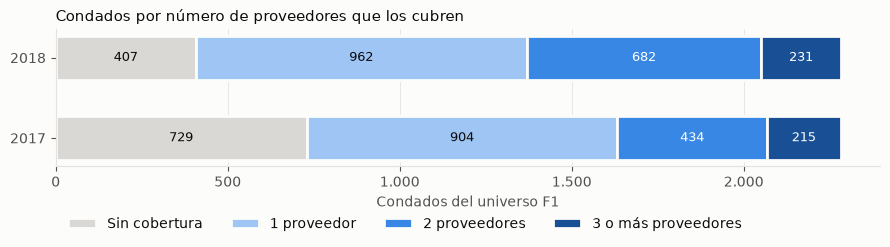

In [30]:
proveedores_condado = (condados.select('IdGeografia', 'Estado')
                       .crossJoin(spark.createDataFrame([(a,) for a in ANIOS], ['Anio']))
                       .join(cobertura.groupBy('Anio', 'IdGeografia').agg(sf.countDistinct('IdProveedor').alias('proveedores')),
                             ['Anio', 'IdGeografia'], 'left')
                       .fillna(0, subset=['proveedores'])
                       .withColumn('rango', when(col('proveedores') >= 3, '3 o más').otherwise(col('proveedores').cast('string')))
                       .cache())
distribucion = (proveedores_condado.groupBy('Anio').pivot('rango', ['0', '1', '2', '3 o más']).count()
                .fillna(0).orderBy('Anio').toPandas().set_index('Anio'))
print('Condados según el número de proveedores que los cubren:')
display(distribucion)
cubiertos = proveedores_condado.filter(col('proveedores') >= 1)
display(cubiertos.groupBy('Anio').agg(
    sf.count('*').alias('condados_cubiertos'),
    sf.sum((col('proveedores') == 1).cast('int')).alias('cubiertos_por_un_solo_proveedor'),
    sf.round(100 * sf.avg((col('proveedores') == 1).cast('int')), 1).alias('pct_un_solo_proveedor'),
).orderBy('Anio').toPandas())

fig, ax = plt.subplots(figsize=(9, 2.8))
izquierda = [0] * len(distribucion)
etiquetas = {'0': 'Sin cobertura', '1': '1 proveedor', '2': '2 proveedores', '3 o más': '3 o más proveedores'}
for color, rango in zip(SECUENCIAL, distribucion.columns):
    valores = distribucion[rango].tolist()
    barras = ax.barh([str(a) for a in distribucion.index], valores, left=izquierda, color=color,
                     edgecolor=COLORES['fondo'], linewidth=2, label=etiquetas[rango], height=0.55)
    for barra, valor, inicio in zip(barras, valores, izquierda):
        if valor > 120:
            ax.text(inicio + valor / 2, barra.get_y() + barra.get_height() / 2, f'{valor:,}'.replace(',', '.'), ha='center', va='center',
                    color=COLORES['texto'] if color in SECUENCIAL[:2] else 'white', fontsize=9)
    izquierda = [i + v for i, v in zip(izquierda, valores)]
ax.xaxis.set_major_formatter(MILES)
ax.set_xlabel('Condados del universo F1')
ax.set_title('Condados por número de proveedores que los cubren', loc='left', fontsize=11)
ax.grid(axis='y', visible=False)
ax.legend(ncol=4, loc='upper left', bbox_to_anchor=(0, -0.28), frameon=False)
fig.tight_layout()
plt.show()

> **2.c:** a nivel de área el 100 % de las áreas tiene un solo proveedor (por construcción), aunque a nivel de condado la pregunta sí es informativa:
>
> * **Más de la mitad de los condados cubiertos depende de un único proveedor**: 904 (58,2 %) en 2017 y 962 (51,3 %) en 2018, además 729 condados en 2017 y 407 en 2018 no tienen ningún plan.
>
> El gráfico muestra que 2018 reduce los condados sin cobertura y aumenta los que tienen 2 proveedores, pero la dependencia de un solo proveedor sigue siendo la situación más común.
>
> **Conclusión del tema 2:** **viable con ajustes.**
>
> * La unidad geográfica debe ser el condado o el estado, no el área de servicio.
> * Se necesita un **maestro oficial de condados** (y de estados) para medir la cobertura frente al país completo, puesto que F1 solo trae 35 estados.
> * Se necesita la **tabla de grupos de áreas de servicio** que menciona la matriz, si RaSA quiere conservar esa agrupación.

### 9.3 Tema 3 · Concentración de planes (análisis 3.a y 3.b)

In [31]:
print('Máximo de planes distintos por área de servicio:',
      cobertura.groupBy('Anio', 'IdAreaDeServicio').agg(sf.countDistinct('IdPlan').alias('p')).agg(sf.max('p')).first()[0])

def planes_por_condado(anio_inicio, anio_fin):
    """Análisis 3.a (ajustado): cuántos y cuáles planes hay por condado en un rango de años."""
    return (cobertura.filter(col('Anio').between(anio_inicio, anio_fin))
            .groupBy('Anio', 'IdGeografia')
            .agg(sf.countDistinct('IdPlan').alias('planes'), sf.countDistinct('IdProveedor').alias('proveedores'),
                 sf.sort_array(sf.collect_set('IdPlan')).alias('lista_planes'))
            .join(condados.select('IdGeografia', 'Estado', 'Condado', 'Poblacion'), 'IdGeografia'))

concentracion = planes_por_condado(2017, 2018).cache()
display(concentracion.groupBy('Anio').agg(
    sf.count('*').alias('condados_con_planes'), sf.round(sf.avg('planes'), 2).alias('planes_promedio'),
    sf.median('planes').alias('planes_mediana'), sf.max('planes').alias('planes_max')).orderBy('Anio').toPandas())
print('Condados con más planes en 2018:')
display(concentracion.filter(col('Anio') == 2018).orderBy(sf.desc('planes'), 'Estado', 'Condado')
        .select('Estado', 'Condado', 'Poblacion', 'planes', 'proveedores', 'lista_planes').limit(5).toPandas())

Máximo de planes distintos por área de servicio: 1


,Anio,condados_con_planes,planes_promedio,planes_mediana,planes_max
0,2017,1553,2.54,2.0,15
1,2018,1875,2.96,3.0,15


Condados con más planes en 2018:


,Estado,Condado,Poblacion,planes,proveedores,lista_planes
0,Wisconsin,Columbia County,58488.0,15,2,"[37833WI0510067-01, 37833WI0510072-02, 94529WI..."
1,Wisconsin,Dane County,563951.0,15,1,"[94529WI0210023-00, 94529WI0210023-01, 94529WI..."
2,Wisconsin,Sauk County,65697.0,15,2,"[37833WI0510067-01, 37833WI0510072-02, 94529WI..."
3,Illinois,Marshall County,11663.0,14,2,"[20129IL0310123-01, 20129IL0330058-06, 20129IL..."
4,Illinois,Peoria County,179432.0,14,2,"[20129IL0310123-01, 20129IL0330058-06, 20129IL..."


> **3.a:**
>
> * Por área de servicio la respuesta es siempre **1 plan** (el área pertenece a un plan), así que la pregunta debe reformularse **por condado o por estado**.
> * Por condado la función devuelve cuántos planes hay y cuáles son (`lista_planes`) para el rango de años elegido, el promedio es de 2,54 planes por condado en 2017 y de 2,96 en 2018, con un máximo de 15.
> * Los condados con más planes en 2018 están en Wisconsin e Illinois y su oferta proviene de solo 1 o 2 proveedores por lo que muchos planes no implican mucha competencia.

,Anio,condados,correlacion_spearman_planes_poblacion,umbral_planes_p25_p75,umbral_poblacion_p25_p75,muchos_planes_poca_poblacion,pocos_planes_mucha_poblacion
0,2017,1553,0.107,"(1.0, 3.0)","(11123, 66146)",78,116
1,2018,1875,0.183,"(1.0, 4.0)","(12777, 77198)",102,138


Ejemplos 2018: condados muy poblados con pocos planes


,Anio,Estado,Condado,Poblacion,planes,planes_por_100k_hab
1070,2018,Arizona,Maricopa County,4496590.0,1,0.022239
1262,2018,Texas,Dallas County,2586050.0,1,0.038669
1267,2018,Texas,Tarrant County,2126480.0,1,0.047026
1519,2018,Florida,Orange County,1422750.0,1,0.070286
1683,2018,Texas,Collin County,1109460.0,1,0.090134


Ejemplos 2018: condados poco poblados con muchos planes


,Anio,Estado,Condado,Poblacion,planes,planes_por_100k_hab
2937,2018,South Dakota,Jones County,879.0,4,455.062571
812,2018,South Dakota,Hyde County,1236.0,4,323.624595
2936,2018,South Dakota,Harding County,1327.0,4,301.431801
1659,2018,South Dakota,Campbell County,1380.0,4,289.855072
2414,2018,Kentucky,Robertson County,2257.0,6,265.839610


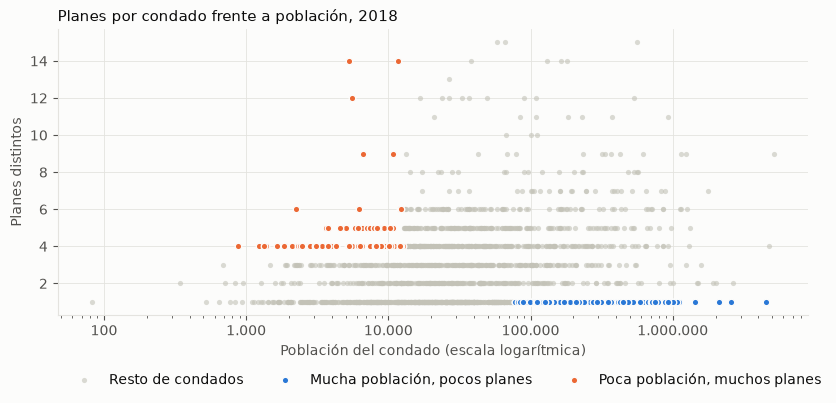

In [32]:
datos_concentracion = concentracion.select('Anio', 'Estado', 'Condado', 'Poblacion', 'planes').toPandas()
datos_concentracion['planes_por_100k_hab'] = datos_concentracion['planes'] / datos_concentracion['Poblacion'] * 100_000

filas = []
marcados = {}
for anio, grupo in datos_concentracion.groupby('Anio'):
    p25_pob, p75_pob = grupo['Poblacion'].quantile([0.25, 0.75])
    p25_planes, p75_planes = grupo['planes'].quantile([0.25, 0.75])
    alta_oferta = (grupo['planes'] >= p75_planes) & (grupo['Poblacion'] <= p25_pob)
    baja_oferta = (grupo['Poblacion'] >= p75_pob) & (grupo['planes'] <= p25_planes)
    marcados[anio] = (alta_oferta, baja_oferta)
    filas.append({'Anio': anio, 'condados': len(grupo),
                  'correlacion_spearman_planes_poblacion': round(grupo['planes'].rank().corr(grupo['Poblacion'].rank()), 3),
                  'umbral_planes_p25_p75': (p25_planes, p75_planes),
                  'umbral_poblacion_p25_p75': (round(p25_pob), round(p75_pob)),
                  'muchos_planes_poca_poblacion': int(alta_oferta.sum()),
                  'pocos_planes_mucha_poblacion': int(baja_oferta.sum())})
display(pd.DataFrame(filas))

ultimo = max(marcados)
grupo = datos_concentracion[datos_concentracion.Anio == ultimo]
alta_oferta, baja_oferta = marcados[ultimo]
print(f'Ejemplos {ultimo}: condados muy poblados con pocos planes')
display(grupo[baja_oferta].sort_values('Poblacion', ascending=False).head(5))
print(f'Ejemplos {ultimo}: condados poco poblados con muchos planes')
display(grupo[alta_oferta].sort_values('planes_por_100k_hab', ascending=False).head(5))

fig, ax = plt.subplots(figsize=(9, 4.2))
resto = ~(alta_oferta | baja_oferta)
ax.scatter(grupo.loc[resto, 'Poblacion'], grupo.loc[resto, 'planes'], s=14, color=COLORES['neutro'],
           alpha=0.6, linewidths=0, label='Resto de condados')
ax.scatter(grupo.loc[baja_oferta, 'Poblacion'], grupo.loc[baja_oferta, 'planes'], s=22, color=COLORES['serie_1'],
           edgecolors=COLORES['fondo'], linewidths=1, label='Mucha población, pocos planes')
ax.scatter(grupo.loc[alta_oferta, 'Poblacion'], grupo.loc[alta_oferta, 'planes'], s=22, color=COLORES['serie_2'],
           edgecolors=COLORES['fondo'], linewidths=1, label='Poca población, muchos planes')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(MILES)
ax.set_xlabel('Población del condado (escala logarítmica)')
ax.set_ylabel('Planes distintos')
ax.set_title(f'Planes por condado frente a población, {ultimo}', loc='left', fontsize=11)
ax.legend(ncol=3, frameon=False, loc='upper left', bbox_to_anchor=(0, -0.16))
fig.tight_layout()
plt.show()

> **3.b:**
>
> * La correlación de rangos entre población y número de planes es **débil**: 0,107 en 2017 y 0,183 en 2018, por lo que la oferta de planes no sigue a la población.
> * Con un criterio simple de cuartiles se identifican dos grupos:
>   * Condados con **mucha población y pocos planes** (posible suboferta, en azul): 116 en 2017 y 138 en 2018, por ejemplo Maricopa County (Arizona con 4,5 millones de habitantes) y Dallas County (Texas con 2,6 millones) cuentan con un solo plan en 2018.
>   * Condados con **poca población y muchos planes** (posible sobreoferta, en naranja): 78 y 102, por ejemplo condados de South Dakota con menos de 1.500 habitantes y 4 planes.
> * El criterio de "no corresponde con la cantidad de habitantes" es un supuesto, dado RaSA debe definir el umbral, por ejemplo planes por cada 100.000 habitantes o desviación frente a lo esperado según la población.
>
> **Conclusión del tema 3:** **viable con ajustes.**
>
> * La unidad debe ser el condado o el estado.
> * La población solo es utilizable tras corregir el factor ×10.000.
> * Falta saber a qué fecha corresponde `PoblacionAct` dado que tiene un único valor por condado sin variación entre 2017 y 2018.

### 9.4 Tema 4 · Evolución de planes (análisis 4.a y 4.b)

In [33]:
print('Valores distintos de Fecha en F3 (crudo):')
display(fuente_planes_beneficio.groupBy('Fecha').count().orderBy('Fecha').toPandas())

costos = (beneficios_plan
          .withColumn('copago_aplica', col('CondicionCopago') != 'Not Applicable')
          .withColumn('coseguro_aplica', col('CondicionCoseguro') != 'Not Applicable'))

def evolucion(por, anio_inicio, anio_fin, tipos=None):
    """Análisis 4.a: evolución de costos por las dimensiones elegidas (tipo de beneficio, proveedor) y año."""
    datos = costos.filter(col('Anio').between(anio_inicio, anio_fin))
    if tipos:
        datos = datos.filter(col('IdTipoBeneficio').isin(tipos))
    return (datos.groupBy(por + ['Anio'])
            .agg(sf.countDistinct('IdPlan').alias('planes'),
                 sf.round(sf.avg(when(col('copago_aplica'), col('valorCopago'))), 2).alias('copago_promedio'),
                 sf.round(sf.avg(when(col('coseguro_aplica'), col('valorCoseguro'))), 2).alias('coseguro_promedio')))

mas_ofrecidos = [r['IdTipoBeneficio'] for r in costos.groupBy('IdTipoBeneficio')
                 .agg(sf.countDistinct('IdPlan').alias('p')).orderBy(sf.desc('p'), 'IdTipoBeneficio').limit(4).collect()]
print('Ejemplo 4.a: evolución de los 4 beneficios ofrecidos por más planes')
display(evolucion(['IdTipoBeneficio', 'NombreBeneficio'], 2017, 2018, mas_ofrecidos)
        .orderBy('IdTipoBeneficio', 'Anio').toPandas())
print('Beneficios distintos ofrecidos por año:')
display(costos.groupBy('Anio').agg(sf.countDistinct('IdTipoBeneficio').alias('tipos_beneficio'),
                                   sf.countDistinct('IdProveedor').alias('proveedores'),
                                   sf.countDistinct('IdPlan').alias('planes')).orderBy('Anio').toPandas())

Valores distintos de Fecha en F3 (crudo):


,Fecha,count
0,1920-12-31,2052
1,2017-12-31,16134
2,2018-12-31,15794
3,"Dec 31,2017",1029
4,"Dec 31,2018",1027


Ejemplo 4.a: evolución de los 4 beneficios ofrecidos por más planes


,IdTipoBeneficio,NombreBeneficio,Anio,planes,copago_promedio,coseguro_promedio
0,190,Dental Check-Up for Children,2017,84,0.00,7.12
1,190,Dental Check-Up for Children,2018,95,0.10,10.75
2,640,Outpatient Rehabilitation Services,2017,83,5.10,34.16
3,640,Outpatient Rehabilitation Services,2018,118,6.89,36.71
4,790,Rehabilitative Occupational and Rehabilitative...,2017,57,6.03,33.18
5,790,Rehabilitative Occupational and Rehabilitative...,2018,107,8.03,37.74
6,795,Rehabilitative Speech Therapy,2017,57,7.13,34.22
7,795,Rehabilitative Speech Therapy,2018,107,7.06,37.92


Beneficios distintos ofrecidos por año:


,Anio,tipos_beneficio,proveedores,planes
0,2017,156,77,202
1,2018,121,90,286


> **4.a:**
>
> * La fecha de F3 toma solo dos valores reales: el 31 de diciembre de 2017 y el de 2018, por lo que los formatos `Dec 31,YYYY` y el año 1920 son variantes erróneas ya corregidas, la evolución "a lo largo del tiempo" se reduce a **dos puntos anuales** y el "rango de fechas" equivale a un rango de años.
> * Los promedios de copago excluyen las filas con condición "Not Applicable" (supuesto) y lo mismo se hace para el coseguro.
> * El conjunto de beneficios, proveedores y planes cambia bastante entre años (156 → 121 tipos de beneficio, 77 → 90 proveedores, 202 → 286 planes) lo que puede sesgar la comparación de promedios.

In [34]:
def cambio_entre_anios(por, anio_inicio, anio_fin):
    """Análisis 4.b: tipos de beneficio (u otra dimensión) que aumentaron o disminuyeron su costo."""
    tabla = evolucion(por, anio_inicio, anio_fin).toPandas()
    pivote = tabla.pivot_table(index=por, columns='Anio', values=['copago_promedio', 'coseguro_promedio'])
    resultado = []
    for medida in ['copago_promedio', 'coseguro_promedio']:
        par = pivote[medida][[anio_inicio, anio_fin]].dropna()
        delta = par[anio_fin] - par[anio_inicio]
        resultado.append({'medida': medida, 'comparables': len(par), 'aumentan': int((delta > 0).sum()),
                          'disminuyen': int((delta < 0).sum()), 'sin_cambio': int((delta == 0).sum())})
    return pd.DataFrame(resultado), pivote

resumen_beneficio, pivote_beneficio = cambio_entre_anios(['IdTipoBeneficio', 'NombreBeneficio'], 2017, 2018)
print('Por tipo de beneficio (promedio de todos los planes de cada año):')
display(resumen_beneficio)
resumen_panel, _ = cambio_entre_anios(['IdProveedor', 'IdTipoBeneficio'], 2017, 2018)
print('Por proveedor y tipo de beneficio (mismo proveedor en ambos años):')
display(resumen_panel)

delta_coseguro = (pivote_beneficio['coseguro_promedio'][2018] - pivote_beneficio['coseguro_promedio'][2017]).dropna()
print('Mayores aumentos y disminuciones del coseguro promedio (puntos porcentuales), 2017 a 2018:')
display(pd.concat([delta_coseguro.sort_values(ascending=False).head(5),
                   delta_coseguro.sort_values().head(5)]).rename('cambio_coseguro').to_frame())

Por tipo de beneficio (promedio de todos los planes de cada año):


,medida,comparables,aumentan,disminuyen,sin_cambio
0,copago_promedio,95,36,45,14
1,coseguro_promedio,99,69,26,4


Por proveedor y tipo de beneficio (mismo proveedor en ambos años):


,medida,comparables,aumentan,disminuyen,sin_cambio
0,copago_promedio,838,97,97,644
1,coseguro_promedio,1152,386,351,415


Mayores aumentos y disminuciones del coseguro promedio (puntos porcentuales), 2017 a 2018:


,,cambio_coseguro
IdTipoBeneficio,NombreBeneficio,
690,Post-Mastectomy Care,33.33
145,Cochlear Implants,25.00
510,Newborn Hearing Screening,17.93
390,Infant Formulas,16.67
765,Private-Duty Nursing,15.53
1050,Wilm's Tumor,-50.00
105,Brain Injury,-39.17
120,Cardiac Rehabilitation,-32.31
160,"Congenital Anomaly, including Cleft Lip/Palate",-25.67


> **4.b:**
>
> * Los datos permiten clasificar cada tipo de beneficio presente en ambos años según si aumentó, disminuyó o mantuvo su costo promedio.
> * **Comparación agregada por beneficio:** el coseguro promedio sube en 69 de 99 beneficios comparables y baja en 26, eso sí el copago es mixto puesto que sube en 36, baja en 45 y no cambia en 14 de 95.
> * **Comparación por mismo proveedor y beneficio** (que controla el cambio en la mezcla de proveedores): el copago no cambia en 644 de 838 casos y el coseguro sube en 386 y baja en 351 de 1.152.
>
> Buena parte del aumento agregado del coseguro se explica por **qué proveedores y planes** están en cada año, más que por alzas de los mismos proveedores, por eso se recomienda esta comparación para el tablero.
>
> **Conclusión del tema 4:** **viable con ajustes y con información adicional.**
>
> * Con dos años la "evolución" es una comparación entre dos períodos.
> * Se requieren los datos de **2019** que RaSA afirmó compartir y que no están en ninguna fuente.
> * Hay que definir si el costo se compara por promedio o mediana, por nivel de servicio y condición de pago y si se pondera por planes o por áreas.

## 10. Conclusión del entendimiento de datos

| Análisis | Veredicto | Ajuste o información requerida |
|---|---|---|
| 1.a Proveedor desleal | Viable con ajustes | Definir umbral relativo o en puntos, tratamiento del 0, nivel de servicio y condición comparables |
| 1.b Proveedores desleales por fechas | Viable con ajustes | Fechas solo anuales y elegir lectura A (dentro del proveedor) o B (frente al mercado) |
| 2.a Nivel de cobertura por años | Viable con ajustes | Medir sobre condados con maestro oficial de condados para el universo del país |
| 2.b Cobertura total de proveedores | Requiere reformulación | Por construcción ningún proveedor cubre todas las áreas debiendo reformular por estado |
| 2.c Áreas con menos de dos proveedores | Requiere reformulación | Por área siempre hay 1 proveedor, lo que se debe medir por condado |
| 3.a Planes por área | Requiere reformulación | Por área siempre hay 1 plan, hay que empezar a medir por condado o estado |
| 3.b Concentración frente a habitantes | Viable con ajustes | Corregir población ×10.000 y definir el criterio de "no corresponde" |
| 4.a Evolución de costos | Viable con información adicional | Solo 2017 y 2018 donde se requieren los datos de 2019 |
| 4.b Beneficios que suben o bajan | Viable con ajustes | Comparar mismo proveedor y beneficio tambien definiendo la medida (promedio o mediana) |

El documento `analisis_entregable_3.md` detalla las columnas de integración, los supuestos, las dudas para RaSA y los análisis adicionales propuestos.

## Cerrar sesión de PySpark

In [35]:
spark.stop()